# Analyse avant ACM - KaraFun

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

## 1. Chargement des données

In [2]:
df = pd.read_csv("../data/raw/td_clustering_karafun.csv")
print(df.shape)
df.head()

(341092, 16)


,id_anonyme,anciennete_client_tr,anciennete_abonnement_tr,statut_abonnement,type_client,type_very_first_abo,type_first_abo_last_streak,ratio_fidelite_tr,methode_paiement,nb_abo_periode,valeur_12M_tr,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,zone_geo,contactable
0,fbb58c58395ab62899c58d6a52f8159ca12ddd7f46bfe2...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Apple,1,00_moins_10,02_1a2,01_1a2,non,US,oui
1,8c981dbb88db4abcfd1c07b30ec42c370195fabaf74b8a...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Android,1,00_moins_10,03_2a3,02_2a3,non,Europe,oui
2,a4b6c3d31fb413aa830dbb423bd3d8446438dae71d9973...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,03_2a3,09_15a20,non,Europe,non
3,ef9a45455295911d59cd8a9c76d32d582709e40a5a238f...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,02_1a2,09_15a20,non,CA,oui
4,91d37bd372c738eddb00a6b2878877161fb26a2a519bf8...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,00_pas_de_session,00_pas_de_session,non,FR,oui


## 2. Types et valeurs manquantes

In [3]:
print(df.dtypes)

id_anonyme                      str
anciennete_client_tr            str
anciennete_abonnement_tr        str
statut_abonnement               str
type_client                     str
type_very_first_abo             str
type_first_abo_last_streak      str
ratio_fidelite_tr               str
methode_paiement                str
nb_abo_periode                int64
valeur_12M_tr                   str
avg_sessions_actifs_tr          str
avg_songs_sessions_tr           str
utilise_remote                  str
zone_geo                        str
contactable                     str
dtype: object


In [4]:
print(df.isna().sum())

id_anonyme                    0
anciennete_client_tr          0
anciennete_abonnement_tr      0
statut_abonnement             0
type_client                   0
type_very_first_abo           0
type_first_abo_last_streak    0
ratio_fidelite_tr             0
methode_paiement              0
nb_abo_periode                0
valeur_12M_tr                 0
avg_sessions_actifs_tr        0
avg_songs_sessions_tr         0
utilise_remote                0
zone_geo                      0
contactable                   0
dtype: int64


In [5]:
print(df.nunique())

id_anonyme                    341092
anciennete_client_tr              20
anciennete_abonnement_tr          20
statut_abonnement                  2
type_client                        4
type_very_first_abo                3
type_first_abo_last_streak         3
ratio_fidelite_tr                  6
methode_paiement                   7
nb_abo_periode                    12
valeur_12M_tr                     12
avg_sessions_actifs_tr            14
avg_songs_sessions_tr             13
utilise_remote                     2
zone_geo                          11
contactable                        2
dtype: int64


In [6]:
print(df["id_anonyme"].duplicated().sum())

0


Pas de valeurs manquantes ni de doublons. nb_abo_periode est la seule variable numérique, à découper en classes.

## 3. Variable nb_abo_periode

In [7]:
print(df["nb_abo_periode"].describe())

count    341092.000000
mean          5.454860
std           4.356785
min           1.000000
25%           1.000000
50%           4.000000
75%          10.000000
max          12.000000
Name: nb_abo_periode, dtype: float64


In [8]:
pct = df["nb_abo_periode"].value_counts(normalize=True).sort_index() * 100
print(pct.round(1))

nb_abo_periode
1     28.5
2     12.0
3      7.5
4      5.5
5      4.5
6      4.3
7      4.6
8      3.1
9      2.8
10     2.7
11     3.6
12    21.0
Name: proportion, dtype: float64


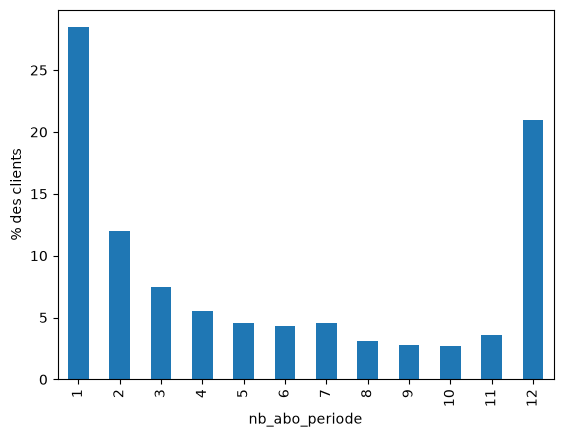

In [9]:
pct.plot(kind="bar")
plt.xlabel("nb_abo_periode")
plt.ylabel("% des clients")
plt.show()

Distribution en U : beaucoup de 1 et de 12.

## 4. Variables qualitatives

In [10]:
variables = [
    "anciennete_client_tr",
    "anciennete_abonnement_tr",
    "statut_abonnement",
    "type_client",
    "type_very_first_abo",
    "type_first_abo_last_streak",
    "ratio_fidelite_tr",
    "methode_paiement",
    "valeur_12M_tr",
    "avg_sessions_actifs_tr",
    "avg_songs_sessions_tr",
    "utilise_remote",
    "zone_geo",
    "contactable",
]

In [11]:
for col in variables:
    pct = df[col].value_counts(normalize=True).sort_index() * 100
    print(pct.round(1))
    print()

anciennete_client_tr
00_moins_1_mois         3.7
01_1_mois               3.7
02_2_mois               3.1
03_3_mois               3.0
04_4_mois               2.9
05_5_mois               3.6
06_6_mois               9.6
07_7a9_mois            10.4
08_10a12_mois           8.9
09_13a15_mois           4.9
10_16a18_mois           6.4
11_19a21_mois           3.9
12_22a24_mois           3.3
13_25a30_mois           7.1
14_31a36_mois           5.1
15_37a48_mois           6.4
16_49a60_mois           3.6
17_61a84_mois           4.4
18_85a120_mois          4.1
19_121_mois_et_plus     2.1
Name: proportion, dtype: float64

anciennete_abonnement_tr
00_moins_1_mois         7.5
01_1_mois               7.2
02_2_mois               5.7
03_3_mois               5.0
04_4_mois               4.9
05_5_mois               5.5
06_6_mois              13.6
07_7a9_mois            14.4
08_10a12_mois          10.7
09_13a15_mois           4.3
10_16a18_mois           4.1
11_19a21_mois           2.7
12_22a24_mois           

### Modalités rares (< 5 %)

In [12]:
for col in variables:
    pct = df[col].value_counts(normalize=True).sort_index() * 100
    rares = pct[pct < 5]
    print(col, ":", len(pct), "modalités dont", len(rares), "sous 5 %")
    print(rares.round(2))
    print()

anciennete_client_tr : 20 modalités dont 13 sous 5 %
anciennete_client_tr
00_moins_1_mois        3.66
01_1_mois              3.72
02_2_mois              3.07
03_3_mois              2.96
04_4_mois              2.88
05_5_mois              3.61
09_13a15_mois          4.91
11_19a21_mois          3.89
12_22a24_mois          3.26
16_49a60_mois          3.57
17_61a84_mois          4.42
18_85a120_mois         4.09
19_121_mois_et_plus    2.09
Name: proportion, dtype: float64

anciennete_abonnement_tr : 20 modalités dont 12 sous 5 %
anciennete_abonnement_tr
04_4_mois              4.90
09_13a15_mois          4.31
10_16a18_mois          4.12
11_19a21_mois          2.73
12_22a24_mois          2.15
13_25a30_mois          3.97
14_31a36_mois          2.41
15_37a48_mois          2.98
16_49a60_mois          1.43
17_61a84_mois          0.88
18_85a120_mois         0.42
19_121_mois_et_plus    0.04
Name: proportion, dtype: float64

statut_abonnement : 2 modalités dont 0 sous 5 %
Series([], Name: proportion,

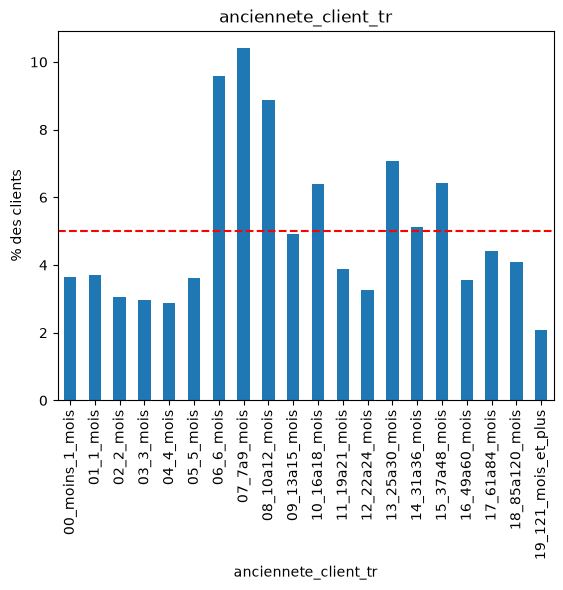

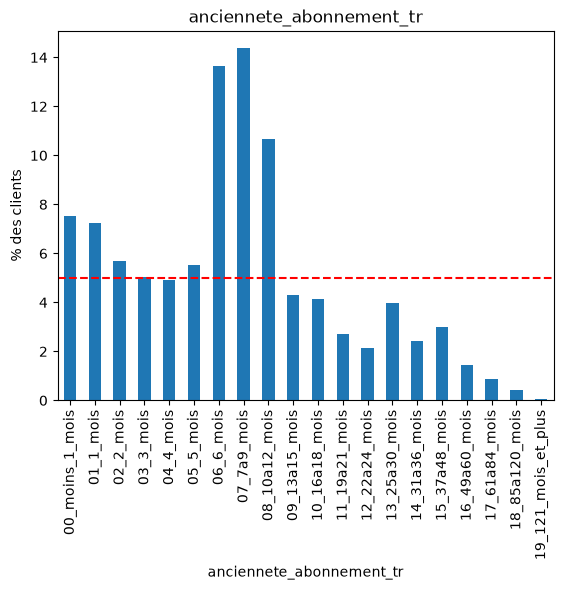

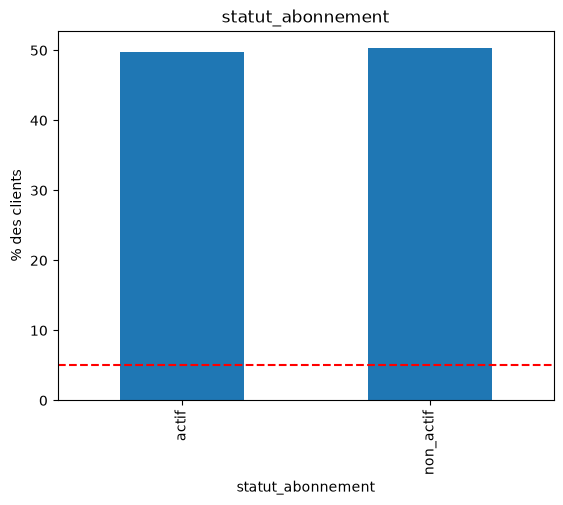

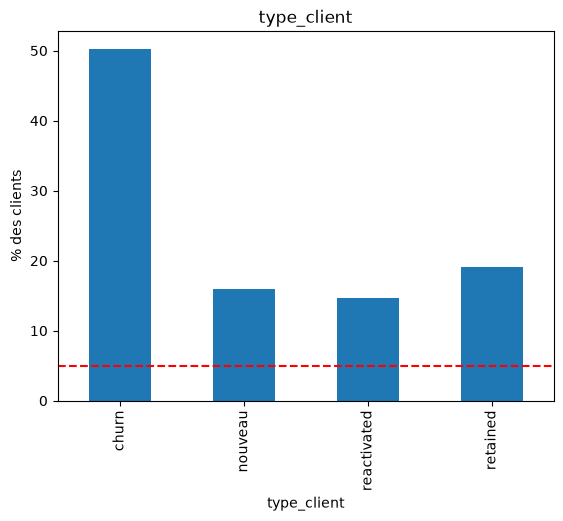

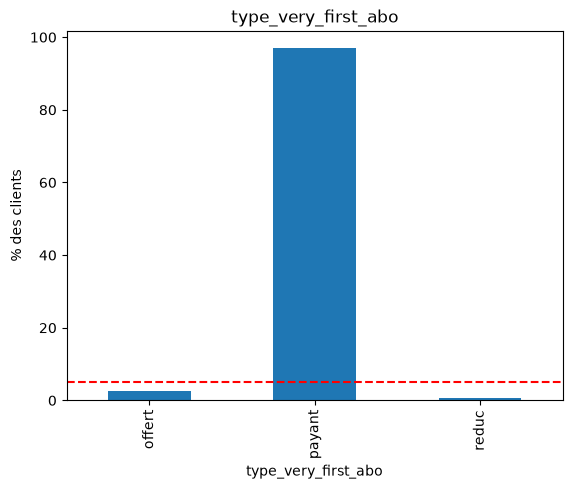

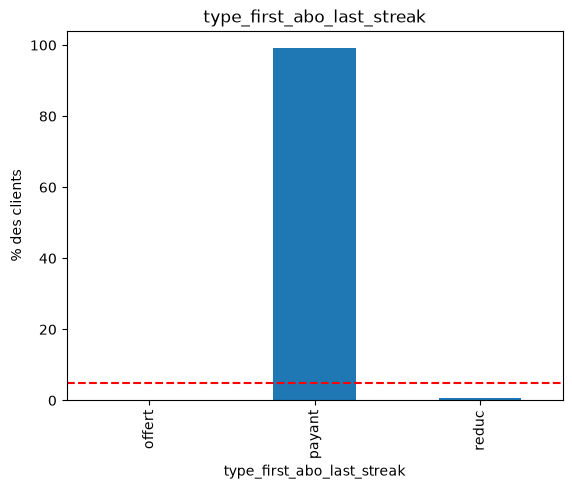

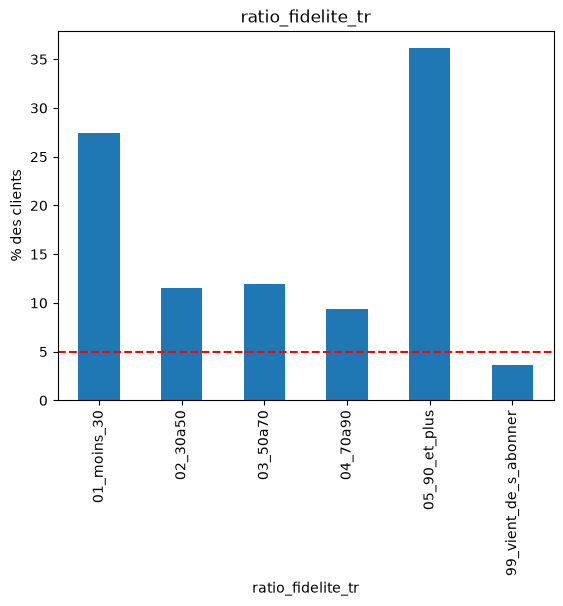

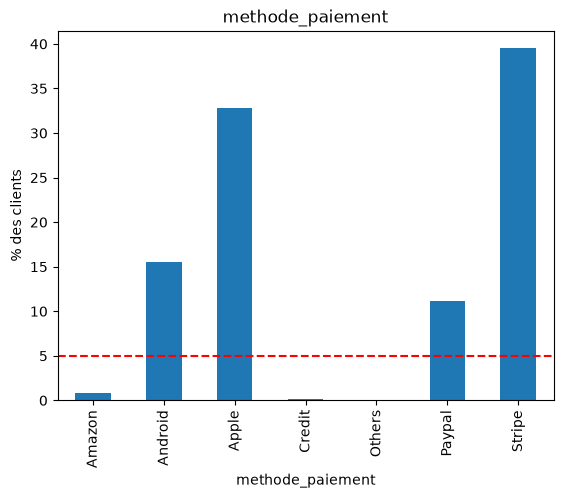

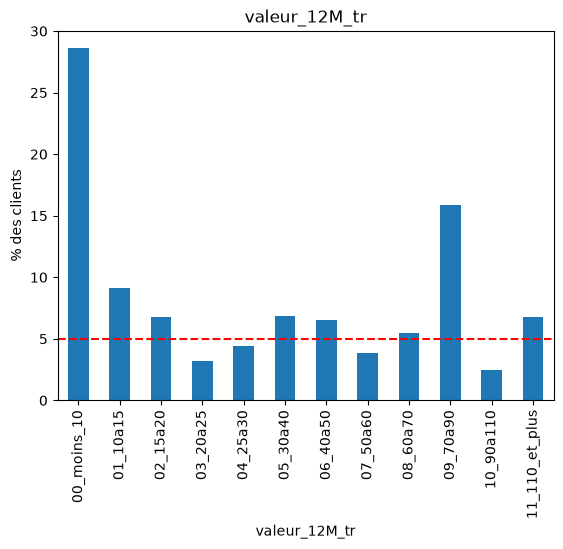

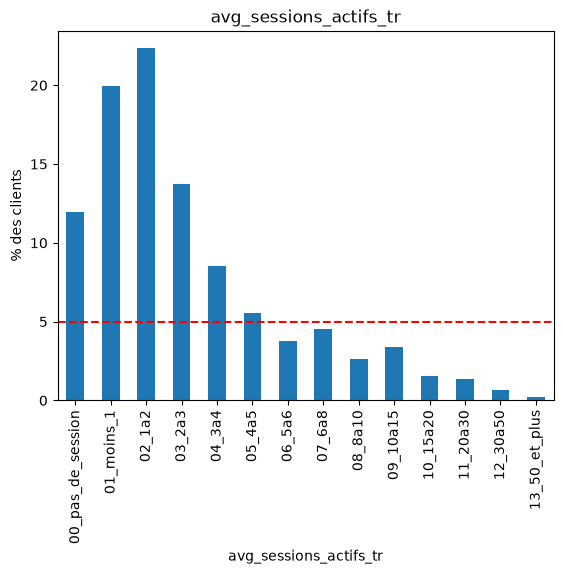

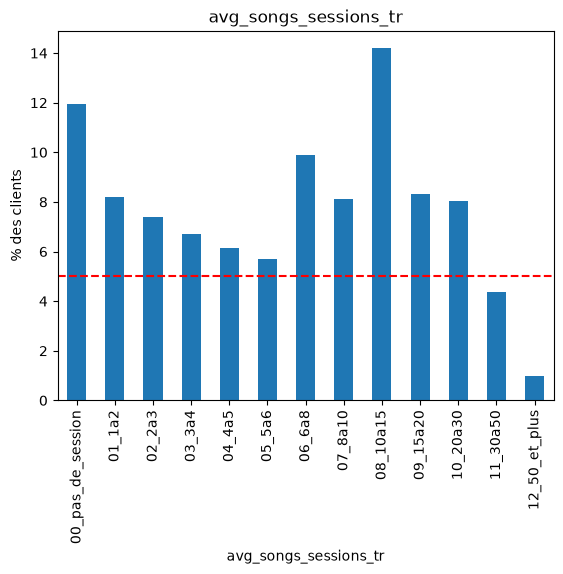

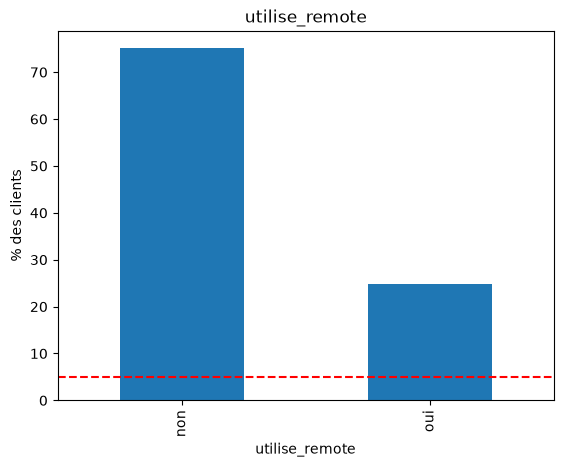

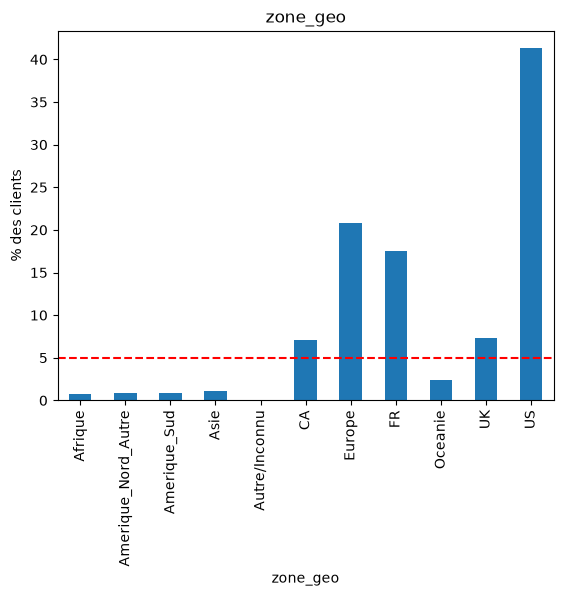

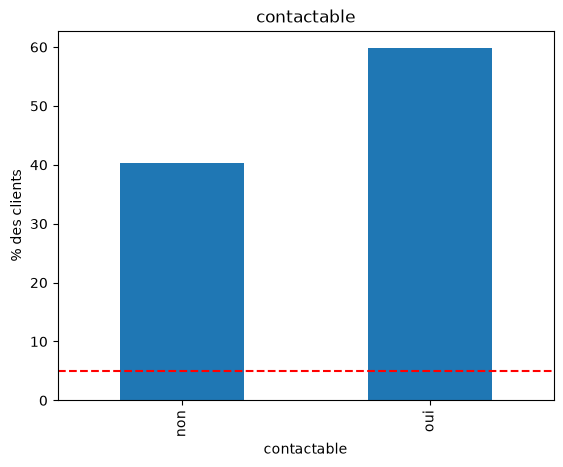

In [13]:
for col in variables:
    pct = df[col].value_counts(normalize=True).sort_index() * 100
    pct.plot(kind="bar")
    plt.axhline(5, color="red", linestyle="--")
    plt.title(col)
    plt.ylabel("% des clients")
    plt.show()

- type_first_abo_last_streak : 99 % payant
- methode_paiement : Others, Credit et Amazon très rares
- zone_geo : plusieurs zones autour de 1 %
- anciennetés, sessions, chansons, valeur : beaucoup de modalités sous 5 %

## 5. V de Cramér

Avec 341 092 lignes le khi-deux est toujours significatif, on regarde plutôt le V de Cramér.

In [14]:
def cramer(var1, var2):
    tableau = pd.crosstab(df[var1], df[var2])
    chi2 = chi2_contingency(tableau)[0]
    n = len(df)
    k = min(tableau.shape) - 1
    return np.sqrt(chi2 / (n * k))

In [15]:
tableau = pd.crosstab(df["type_client"], df["utilise_remote"])
print(tableau)

resultat = chi2_contingency(tableau)
print("khi2 :", resultat[0])
print("p-value :", resultat[1])
print("V de Cramer :", cramer("type_client", "utilise_remote"))

utilise_remote     non    oui
type_client                  
churn           131888  39598
nouveau          38907  15714
reactivated      33522  16343
retained         51747  13373
khi2 : 3051.599615801947
p-value : 0.0
V de Cramer : 0.09458625030115726


p-value = 0 mais V = 0,09.

### Matrice des V de Cramér

In [16]:
variables2 = variables + ["nb_abo_periode"]

matrice = pd.DataFrame(index=variables2, columns=variables2, dtype=float)

for v1 in variables2:
    for v2 in variables2:
        matrice.loc[v1, v2] = cramer(v1, v2)

matrice.round(2)

,anciennete_client_tr,anciennete_abonnement_tr,statut_abonnement,type_client,type_very_first_abo,type_first_abo_last_streak,ratio_fidelite_tr,methode_paiement,valeur_12M_tr,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,zone_geo,contactable,nb_abo_periode
anciennete_client_tr,1.00,0.55,0.32,0.44,0.13,0.05,0.50,0.06,0.22,0.07,0.05,0.07,0.04,0.35,0.26
anciennete_abonnement_tr,0.55,1.00,0.48,0.54,0.07,0.08,0.40,0.08,0.25,0.10,0.07,0.14,0.05,0.18,0.29
statut_abonnement,0.32,0.48,1.00,1.00,0.07,0.01,0.69,0.08,0.62,0.27,0.17,0.04,0.12,0.03,0.64
type_client,0.44,0.54,1.00,1.00,0.16,0.02,0.51,0.08,0.53,0.18,0.12,0.09,0.08,0.17,0.59
type_very_first_abo,0.13,0.07,0.07,0.16,1.00,0.35,0.09,0.07,0.04,0.03,0.05,0.05,0.04,0.05,0.07
type_first_abo_last_streak,0.05,0.08,0.01,0.02,0.35,1.00,0.02,0.64,0.02,0.02,0.02,0.03,0.02,0.04,0.04
ratio_fidelite_tr,0.50,0.40,0.69,0.51,0.09,0.02,1.00,0.04,0.39,0.16,0.06,0.02,0.07,0.12,0.41
methode_paiement,0.06,0.08,0.08,0.08,0.07,0.64,0.04,1.00,0.16,0.03,0.07,0.07,0.11,0.20,0.05
valeur_12M_tr,0.22,0.25,0.62,0.53,0.04,0.02,0.39,0.16,1.00,0.13,0.05,0.06,0.12,0.12,0.63
avg_sessions_actifs_tr,0.07,0.10,0.27,0.18,0.03,0.02,0.16,0.03,0.13,1.00,0.30,0.21,0.04,0.09,0.13


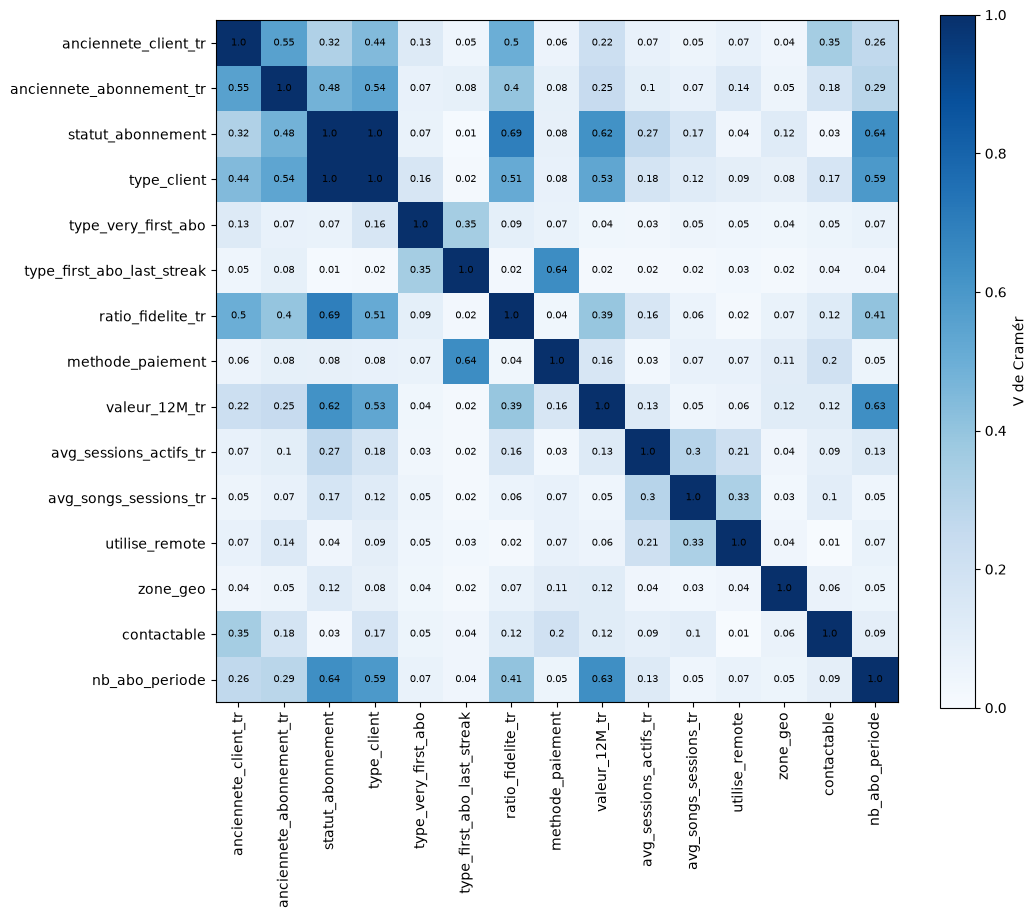

In [17]:
plt.figure(figsize=(11, 9))
plt.imshow(matrice, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="V de Cramér")
plt.xticks(range(len(variables2)), variables2, rotation=90)
plt.yticks(range(len(variables2)), variables2)

for i in range(len(variables2)):
    for j in range(len(variables2)):
        plt.text(j, i, round(matrice.iloc[i, j], 2), ha="center", va="center", fontsize=7)

plt.show()

In [18]:
couples = []
for i in range(len(variables2)):
    for j in range(i + 1, len(variables2)):
        couples.append([variables2[i], variables2[j], round(matrice.iloc[i, j], 3)])

classement = pd.DataFrame(couples, columns=["variable_1", "variable_2", "V"])
classement = classement.sort_values("V", ascending=False)
classement.head(20)

,variable_1,variable_2,V
27,statut_abonnement,type_client,1.000
30,statut_abonnement,ratio_fidelite_tr,0.693
61,type_first_abo_last_streak,methode_paiement,0.644
38,statut_abonnement,nb_abo_periode,0.635
89,valeur_12M_tr,nb_abo_periode,0.633
32,statut_abonnement,valeur_12M_tr,0.621
49,type_client,nb_abo_periode,0.592
0,anciennete_client_tr,anciennete_abonnement_tr,0.555
15,anciennete_abonnement_tr,type_client,0.537
43,type_client,valeur_12M_tr,0.532


## 6. Tableaux croisés des couples les plus liés

### statut_abonnement et type_client (V = 1)

In [19]:
pd.crosstab(df["type_client"], df["statut_abonnement"])

statut_abonnement,actif,non_actif
type_client,,
churn,0,171486
nouveau,54621,0
reactivated,49865,0
retained,65120,0


churn = non_actif, le reste = actif. Même info, on enlève statut_abonnement.

### type_very_first_abo et type_first_abo_last_streak

In [20]:
pd.crosstab(df["type_very_first_abo"], df["type_first_abo_last_streak"])

type_first_abo_last_streak,offert,payant,reduc
type_very_first_abo,,,
offert,119,8239,108
payant,537,328794,1252
reduc,6,908,1129


### methode_paiement et type_first_abo_last_streak (V = 0,64)

In [21]:
pd.crosstab(df["methode_paiement"], df["type_first_abo_last_streak"])

type_first_abo_last_streak,offert,payant,reduc
methode_paiement,,,
Amazon,0,2846,0
Android,3,52883,1
Apple,2,111734,191
Credit,573,29,0
Others,0,1,0
Paypal,26,37426,651
Stripe,58,133022,1646


Le lien vient de Credit (573 sur 602 en offert), soit 0,2 % des clients.

### anciennete_client_tr et ratio_fidelite_tr

In [22]:
pd.crosstab(df["anciennete_client_tr"] == "00_moins_1_mois",
            df["ratio_fidelite_tr"] == "99_vient_de_s_abonner")

ratio_fidelite_tr,False,True
anciennete_client_tr,,
False,328618,0
True,0,12474


Les 12 474 clients de moins d'1 mois = "vient de s'abonner".

### avg_sessions_actifs_tr et avg_songs_sessions_tr

In [23]:
pd.crosstab(df["avg_sessions_actifs_tr"] == "00_pas_de_session",
            df["avg_songs_sessions_tr"] == "00_pas_de_session")

avg_songs_sessions_tr,False,True
avg_sessions_actifs_tr,,
False,300376,0
True,0,40716


Pareil, les 40 716 sans session sont les mêmes dans les deux.

### nb_abo_periode et valeur_12M_tr (V = 0,63)

In [24]:
tableau = pd.crosstab(df["nb_abo_periode"], df["valeur_12M_tr"], normalize="index") * 100
tableau.round(1)

valeur_12M_tr,00_moins_10,01_10a15,02_15a20,03_20a25,04_25a30,05_30a40,06_40a50,07_50a60,08_60a70,09_70a90,10_90a110,11_110_et_plus
nb_abo_periode,,,,,,,,,,,,
1,98.7,1.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.9,71.9,23.9,0.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.1,1.7,51.6,24.3,22.0,0.3,0.0,0.0,0.0,0.0,0.0,0.0
4,0.1,0.1,0.8,24.5,46.3,28.1,0.1,0.0,0.0,0.0,0.0,0.0
5,0.0,0.1,0.1,0.3,4.6,69.2,25.7,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.1,0.0,0.1,48.7,25.7,25.2,0.1,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.1,0.5,71.1,4.0,24.2,0.1,0.0,0.0
8,0.0,0.1,0.0,0.0,0.0,0.1,31.5,38.4,3.2,26.6,0.0,0.0
9,0.1,0.0,0.0,0.0,0.0,0.0,0.2,46.9,22.5,30.2,0.1,0.0


Plus il y a d'abonnements, plus la valeur est élevée. Lien fort mais on garde les deux.

### anciennete_client_tr et anciennete_abonnement_tr (V = 0,55)

In [25]:
tableau = pd.crosstab(df["anciennete_client_tr"], df["anciennete_abonnement_tr"], normalize="index") * 100
tableau.round(1)

anciennete_abonnement_tr,00_moins_1_mois,01_1_mois,02_2_mois,03_3_mois,04_4_mois,05_5_mois,06_6_mois,07_7a9_mois,08_10a12_mois,09_13a15_mois,10_16a18_mois,11_19a21_mois,12_22a24_mois,13_25a30_mois,14_31a36_mois,15_37a48_mois,16_49a60_mois,17_61a84_mois,18_85a120_mois,19_121_mois_et_plus
anciennete_client_tr,,,,,,,,,,,,,,,,,,,,
00_moins_1_mois,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
01_1_mois,2.0,98.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
02_2_mois,3.1,1.8,95.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
03_3_mois,3.1,2.9,1.6,92.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
04_4_mois,2.6,2.9,2.6,1.3,90.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
05_5_mois,2.4,2.7,2.0,1.8,1.3,89.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
06_6_mois,3.6,2.2,1.8,1.7,1.8,0.9,88.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
07_7a9_mois,3.2,3.6,2.8,2.0,1.7,1.9,2.7,82.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
08_10a12_mois,3.9,3.0,2.5,2.2,2.4,2.4,4.0,5.2,74.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Le haut du tableau est à 0 (l'abonnement ne peut pas être plus ancien que le client).

## 7. Lien de chaque variable avec type_client

type_first_abo_last_streak    0.02
methode_paiement              0.08
zone_geo                      0.08
utilise_remote                0.09
avg_songs_sessions_tr         0.12
type_very_first_abo           0.16
contactable                   0.17
avg_sessions_actifs_tr        0.18
anciennete_client_tr          0.44
ratio_fidelite_tr             0.51
valeur_12M_tr                 0.53
anciennete_abonnement_tr      0.54
nb_abo_periode                0.59
statut_abonnement             1.00
Name: type_client, dtype: float64


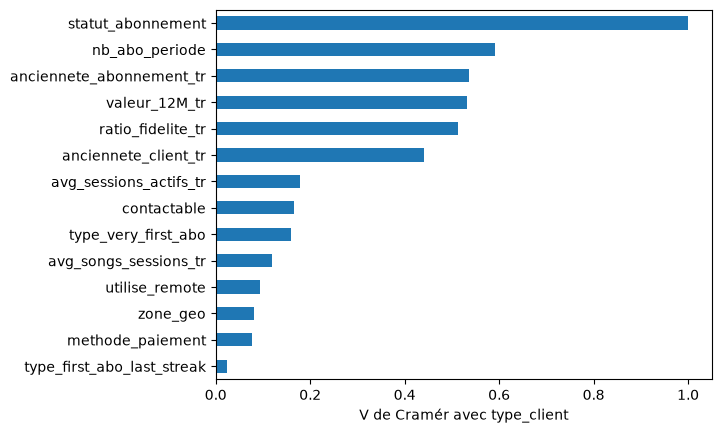

In [26]:
lien = matrice["type_client"].drop("type_client").sort_values()
print(lien.round(2))

lien.plot(kind="barh")
plt.xlabel("V de Cramér avec type_client")
plt.show()

## 8. Conclusion

À enlever : id_anonyme, statut_abonnement (doublon de type_client), type_first_abo_last_streak (ou en illustrative).

Illustratives : type_client, contactable.

Regroupements :
- nb_abo_periode en classes (1 et 12 à part)
- methode_paiement : Others, Credit, Amazon
- zone_geo : petites zones
- type_very_first_abo / type_first_abo_last_streak : offert + reduc
- anciennetés, sessions, chansons, valeur : 5-6 classes

## 9. Regroupements

On travaille sur une copie df2.

In [27]:
df2 = df.copy()
print(df2.shape)

(341092, 16)


### 9.1 nb_abo_periode

5 classes, 1 et 12 à part.

In [28]:
groupes_nb_abo = {
    1: "01_1_abo",
    2: "02_2a3_abo",
    3: "02_2a3_abo",
    4: "03_4a6_abo",
    5: "03_4a6_abo",
    6: "03_4a6_abo",
    7: "04_7a11_abo",
    8: "04_7a11_abo",
    9: "04_7a11_abo",
    10: "04_7a11_abo",
    11: "04_7a11_abo",
    12: "05_12_abo",
}

df2["nb_abo_periode"] = df2["nb_abo_periode"].map(groupes_nb_abo)

In [29]:
pct = df2["nb_abo_periode"].value_counts(normalize=True).sort_index() * 100
print(pct.round(1))

nb_abo_periode
01_1_abo       28.5
02_2a3_abo     19.5
03_4a6_abo     14.4
04_7a11_abo    16.7
05_12_abo      21.0
Name: proportion, dtype: float64


Plus de modalité rare (14 % à 29 %).

### 9.2 methode_paiement

In [30]:
print(df2["methode_paiement"].value_counts())

methode_paiement
Stripe     134726
Apple      111927
Android     52887
Paypal      38103
Amazon       2846
Credit        602
Others          1
Name: count, dtype: int64


Others = 1 seul client, on supprime la ligne.

In [31]:
df2 = df2[df2["methode_paiement"] != "Others"]
print(df2.shape)

(341091, 16)


#### Credit : Paypal ou Stripe ?

In [32]:
autres_variables = [
    "type_client",
    "zone_geo",
    "nb_abo_periode",
    "valeur_12M_tr",
    "ratio_fidelite_tr",
    "anciennete_client_tr",
    "anciennete_abonnement_tr",
    "type_very_first_abo",
    "type_first_abo_last_streak",
    "avg_sessions_actifs_tr",
    "avg_songs_sessions_tr",
    "utilise_remote",
    "contactable",
]

In [33]:
for var in ["type_client", "nb_abo_periode", "valeur_12M_tr", "zone_geo", "utilise_remote"]:
    tableau = pd.crosstab(df2["methode_paiement"], df2[var], normalize="index") * 100
    print(tableau.loc[["Credit", "Paypal", "Stripe"]].round(1))
    print()

type_client       churn  nouveau  reactivated  retained
methode_paiement                                       
Credit             71.1      0.7         27.4       0.8
Paypal             46.2     13.5         10.8      29.5
Stripe             46.8     16.1         16.3      20.9

nb_abo_periode    01_1_abo  02_2a3_abo  03_4a6_abo  04_7a11_abo  05_12_abo
methode_paiement                                                          
Credit                 0.7        59.8        19.6         17.3        2.7
Paypal                26.0        17.3        12.0         14.3       30.4
Stripe                25.4        19.3        15.0         17.8       22.5

valeur_12M_tr     00_moins_10  01_10a15  02_15a20  03_20a25  04_25a30  \
methode_paiement                                                        
Credit                   47.7      15.3       9.0       4.0       5.3   
Paypal                   26.4       7.5       5.7       2.2       4.8   
Stripe                   26.1       5.6       8.9  

Écart entre deux lignes = somme des différences de % / 2 (0 = même répartition, 100 = rien en commun).

In [34]:
def ecart(modalite1, modalite2, var):
    tableau = pd.crosstab(df2["methode_paiement"], df2[var], normalize="index") * 100
    difference = tableau.loc[modalite1] - tableau.loc[modalite2]
    return difference.abs().sum() / 2

In [35]:
lignes = []
for var in autres_variables:
    lignes.append([var, ecart("Credit", "Paypal", var), ecart("Credit", "Stripe", var)])

ecarts_credit = pd.DataFrame(lignes, columns=["variable", "Credit_Paypal", "Credit_Stripe"])
ecarts_credit.round(1)

,variable,Credit_Paypal,Credit_Stripe
0,type_client,41.5,35.5
1,zone_geo,27.3,11.4
2,nb_abo_periode,53.1,45.1
3,valeur_12M_tr,36.8,34.6
4,ratio_fidelite_tr,32.1,30.2
5,anciennete_client_tr,26.9,22.8
6,anciennete_abonnement_tr,46.1,38.5
7,type_very_first_abo,7.6,6.3
8,type_first_abo_last_streak,95.1,95.1
9,avg_sessions_actifs_tr,16.7,14.9


In [36]:
print(ecarts_credit[["Credit_Paypal", "Credit_Stripe"]].mean().round(1))

Credit_Paypal    33.6
Credit_Stripe    29.2
dtype: float64


Credit est plus proche de Stripe sur 12 variables sur 13 (écart moyen 29,2 contre 33,6) donc on le met avec Stripe. Les écarts restent grands (71 % de churn, 95 % offert) mais ce ne sont que 602 clients.

#### Amazon : Android ou Apple ?

In [37]:
for var in ["type_client", "nb_abo_periode", "valeur_12M_tr", "zone_geo", "utilise_remote"]:
    tableau = pd.crosstab(df2["methode_paiement"], df2[var], normalize="index") * 100
    print(tableau.loc[["Amazon", "Android", "Apple"]].round(1))
    print()

type_client       churn  nouveau  reactivated  retained
methode_paiement                                       
Amazon             42.1     26.8         12.8      18.4
Android            52.9     18.2         14.4      14.4
Apple              54.7     15.5         14.0      15.7

nb_abo_periode    01_1_abo  02_2a3_abo  03_4a6_abo  04_7a11_abo  05_12_abo
methode_paiement                                                          
Amazon                20.8        19.7        16.8         23.5       19.2
Android               30.8        20.6        14.6         17.1       16.9
Apple                 32.2        19.6        14.3         15.8       18.1

valeur_12M_tr     00_moins_10  01_10a15  02_15a20  03_20a25  04_25a30  \
methode_paiement                                                        
Amazon                   20.8      11.3       7.7       0.5       5.4   
Android                  30.9      12.6       0.2       7.7       5.5   
Apple                    31.3      12.2       7.6  

In [38]:
lignes = []
for var in autres_variables:
    lignes.append([var, ecart("Amazon", "Android", var), ecart("Amazon", "Apple", var)])

ecarts_amazon = pd.DataFrame(lignes, columns=["variable", "Amazon_Android", "Amazon_Apple"])
ecarts_amazon.round(1)

,variable,Amazon_Android,Amazon_Apple
0,type_client,12.6,13.9
1,zone_geo,28.8,13.8
2,nb_abo_periode,10.9,11.4
3,valeur_12M_tr,20.8,16.7
4,ratio_fidelite_tr,9.7,13.2
5,anciennete_client_tr,11.6,12.8
6,anciennete_abonnement_tr,14.3,13.6
7,type_very_first_abo,0.9,1.0
8,type_first_abo_last_streak,0.0,0.2
9,avg_sessions_actifs_tr,22.9,25.0


In [39]:
print(ecarts_amazon[["Amazon_Android", "Amazon_Apple"]].mean().round(1))

Amazon_Android    12.2
Amazon_Apple      12.1
dtype: float64


Écart moyen quasi identique (12,2 / 12,1). Android est plus proche sur 10 variables sur 13, Apple surtout sur zone_geo. On met Amazon avec Android (l'Appstore Amazon tourne sur Android).

#### Regroupement

In [40]:
df2["methode_paiement"] = df2["methode_paiement"].replace({"Credit": "Stripe", "Amazon": "Android"})

pct = df2["methode_paiement"].value_counts(normalize=True) * 100
print(df2["methode_paiement"].value_counts())
print(pct.round(1))

methode_paiement
Stripe     135328
Apple      111927
Android     55733
Paypal      38103
Name: count, dtype: int64
methode_paiement
Stripe     39.7
Apple      32.8
Android    16.3
Paypal     11.2
Name: proportion, dtype: float64


### 9.3 zone_geo

On supprime Autre/Inconnu (22 clients) et on regroupe les petites zones.

In [41]:
df2 = df2[df2["zone_geo"] != "Autre/Inconnu"]
print(df2.shape)

(341069, 16)


In [42]:
groupes_zone = {
    "Afrique": "Reste_du_monde",
    "Asie": "Reste_du_monde",
    "Amerique_Sud": "Reste_du_monde",
    "Amerique_Nord_Autre": "Reste_du_monde",
    "Oceanie": "Reste_du_monde",
}

df2["zone_geo"] = df2["zone_geo"].replace(groupes_zone)

pct = df2["zone_geo"].value_counts(normalize=True) * 100
print(df2["zone_geo"].value_counts())
print(pct.round(1))

zone_geo
US                140841
Europe             71144
FR                 59810
UK                 25026
CA                 23999
Reste_du_monde     20249
Name: count, dtype: int64
zone_geo
US                41.3
Europe            20.9
FR                17.5
UK                 7.3
CA                 7.0
Reste_du_monde     5.9
Name: proportion, dtype: float64


Reste_du_monde = 5,9 %.

### 9.4 type_very_first_abo et type_first_abo_last_streak

offert + reduc -> offert_reduc

In [43]:
for var in ["type_very_first_abo", "type_first_abo_last_streak"]:
    pct = df2[var].value_counts(normalize=True) * 100
    print(pct.round(1))
    print()

type_very_first_abo
payant    96.9
offert     2.5
reduc      0.6
Name: proportion, dtype: float64

type_first_abo_last_streak
payant    99.1
reduc      0.7
offert     0.2
Name: proportion, dtype: float64



In [44]:
groupes_type_abo = {
    "offert": "offert_reduc",
    "reduc": "offert_reduc",
}

for var in ["type_very_first_abo", "type_first_abo_last_streak"]:
    df2[var] = df2[var].replace(groupes_type_abo)

    pct = df2[var].value_counts(normalize=True) * 100
    print(df2[var].value_counts())
    print(pct.round(1))
    print()

type_very_first_abo
payant          330561
offert_reduc     10508
Name: count, dtype: int64
type_very_first_abo
payant          96.9
offert_reduc     3.1
Name: proportion, dtype: float64

type_first_abo_last_streak
payant          337918
offert_reduc      3151
Name: count, dtype: int64
type_first_abo_last_streak
payant          99.1
offert_reduc     0.9
Name: proportion, dtype: float64



type_very_first_abo : offert_reduc = 3,1 %.

type_first_abo_last_streak : seulement 0,9 %, toujours rare -> à enlever ou en illustrative.

### 9.5 Variables en tranches

Avant de fusionner deux tranches on vérifie qu'elles se ressemblent, avec le même écart que pour Credit / Amazon.

In [45]:
variables_tranches = [
    "anciennete_client_tr",
    "anciennete_abonnement_tr",
    "valeur_12M_tr",
    "avg_sessions_actifs_tr",
    "avg_songs_sessions_tr",
]

variables_croisement = autres_variables + ["methode_paiement"]

ecarts_voisins : écart entre chaque tranche et la suivante (on ne fusionne que des tranches voisines).

In [46]:
def ecarts_voisins(var):
    modalites = sorted(df2[var].unique())
    resultat = pd.DataFrame()
    for v in variables_croisement:
        if v != var:
            tableau = pd.crosstab(df2[var], df2[v], normalize="index") * 100
            for i in range(len(modalites) - 1):
                difference = tableau.loc[modalites[i]] - tableau.loc[modalites[i + 1]]
                resultat.loc[modalites[i] + " / " + modalites[i + 1], v] = difference.abs().sum() / 2
    resultat["moyenne"] = resultat.mean(axis=1)
    return resultat

ecarts_classes : écart entre chaque tranche et la classe où on la met.

In [47]:
def ecarts_classes(var, groupes):
    classes = df2[var].map(groupes)
    detail = pd.DataFrame()
    for v in variables_croisement:
        if v != var:
            tableau_modalites = pd.crosstab(df2[var], df2[v], normalize="index") * 100
            tableau_classes = pd.crosstab(classes, df2[v], normalize="index") * 100
            for modalite in sorted(groupes):
                difference = tableau_modalites.loc[modalite] - tableau_classes.loc[groupes[modalite]]
                detail.loc[modalite, v] = difference.abs().sum() / 2

    resultat = pd.DataFrame({
        "classe": pd.Series(groupes),
        "pct_clients": df2[var].value_counts(normalize=True) * 100,
        "ecart_moyen": detail.mean(axis=1),
    })
    return resultat.sort_index()

Règles :
- on ne fusionne que des tranches voisines
- sous 2 % : toujours fusionnée
- entre 2 et 5 % : fusionnée si elle ressemble à sa classe, sinon gardée seule
- au-dessus de 5 % : on fusionne pour avoir 5 à 7 modalités

#### anciennete_client_tr

In [48]:
tableau = pd.crosstab(df2["anciennete_client_tr"], df2["type_client"], normalize="index") * 100
tableau.round(1)

type_client,churn,nouveau,reactivated,retained
anciennete_client_tr,,,,
00_moins_1_mois,0.0,100.0,0.0,0.0
01_1_mois,38.1,59.9,2.0,0.0
02_2_mois,51.8,43.9,4.3,0.0
03_3_mois,55.0,39.4,5.5,0.0
04_4_mois,60.1,33.6,6.3,0.0
05_5_mois,64.0,29.8,6.2,0.0
06_6_mois,72.0,20.9,7.1,0.0
07_7a9_mois,67.1,22.2,10.6,0.0
08_10a12_mois,65.2,14.2,14.3,6.3


In [49]:
ecarts_voisins("anciennete_client_tr").round(1)

,type_client,zone_geo,nb_abo_periode,valeur_12M_tr,ratio_fidelite_tr,anciennete_abonnement_tr,type_very_first_abo,type_first_abo_last_streak,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,contactable,methode_paiement,moyenne
00_moins_1_mois / 01_1_mois,40.1,1.7,53.4,53.2,100.0,98.0,0.0,0.1,11.8,3.7,3.6,0.4,1.3,28.2
01_1_mois / 02_2_mois,16.0,1.9,5.7,33.8,40.9,96.2,0.1,0.1,5.1,5.5,7.0,0.8,1.2,16.5
02_2_mois / 03_3_mois,4.5,3.0,39.5,28.6,38.2,93.5,1.1,1.0,5.6,5.3,1.6,0.2,1.0,17.2
03_3_mois / 04_4_mois,5.9,1.3,2.3,24.9,45.4,91.6,2.7,2.3,2.1,2.3,0.6,0.1,1.8,14.1
04_4_mois / 05_5_mois,3.8,2.5,3.1,9.8,14.4,90.2,2.6,2.3,5.5,2.0,0.4,0.8,5.4,11.0
05_5_mois / 06_6_mois,9.0,11.3,27.6,20.6,12.8,89.7,1.1,0.2,3.5,3.6,1.2,1.7,2.1,14.2
06_6_mois / 07_7a9_mois,4.9,9.4,11.7,21.5,7.9,85.7,1.5,0.3,3.4,5.1,1.6,0.0,5.6,12.2
07_7a9_mois / 08_10a12_mois,10.0,2.1,14.2,15.9,4.4,77.7,1.3,0.1,5.4,5.1,8.1,6.7,2.5,11.8
08_10a12_mois / 09_13a15_mois,28.8,3.9,17.8,18.4,26.3,68.0,2.5,0.3,17.2,12.0,3.0,4.1,3.0,15.8
09_13a15_mois / 10_16a18_mois,2.0,3.9,5.9,5.1,8.3,55.2,1.1,0.2,5.3,3.0,0.5,2.2,3.6,7.4


Écarts grands avec anciennete_abonnement_tr (normal). Avant 13 mois les tranches sont assez différentes (11 à 28), après elles se ressemblent (3 à 8). Grosse coupure entre 10-12 et 13-15 mois (15,8), là où arrivent les retained.

On teste les 6 classes de regroupements.py.

In [50]:
groupes_anciennete_client = {
    "00_moins_1_mois":     "01_moins_3_mois",
    "01_1_mois":           "01_moins_3_mois",
    "02_2_mois":           "01_moins_3_mois",
    "03_3_mois":           "02_3a5_mois",
    "04_4_mois":           "02_3a5_mois",
    "05_5_mois":           "02_3a5_mois",
    "06_6_mois":           "03_6a12_mois",
    "07_7a9_mois":         "03_6a12_mois",
    "08_10a12_mois":       "03_6a12_mois",
    "09_13a15_mois":       "04_13a24_mois",
    "10_16a18_mois":       "04_13a24_mois",
    "11_19a21_mois":       "04_13a24_mois",
    "12_22a24_mois":       "04_13a24_mois",
    "13_25a30_mois":       "05_25a48_mois",
    "14_31a36_mois":       "05_25a48_mois",
    "15_37a48_mois":       "05_25a48_mois",
    "16_49a60_mois":       "06_49_mois_et_plus",
    "17_61a84_mois":       "06_49_mois_et_plus",
    "18_85a120_mois":      "06_49_mois_et_plus",
    "19_121_mois_et_plus": "06_49_mois_et_plus",
}

ecarts_classes("anciennete_client_tr", groupes_anciennete_client).round(1)

,classe,pct_clients,ecart_moyen
00_moins_1_mois,01_moins_3_mois,3.7,18.7
01_1_mois,01_moins_3_mois,3.7,13.2
02_2_mois,01_moins_3_mois,3.1,15.0
03_3_mois,02_3a5_mois,3.0,10.0
04_4_mois,02_3a5_mois,2.9,7.8
05_5_mois,02_3a5_mois,3.6,7.6
06_6_mois,03_6a12_mois,9.6,8.9
07_7a9_mois,03_6a12_mois,10.4,6.6
08_10a12_mois,03_6a12_mois,8.9,8.8
09_13a15_mois,04_13a24_mois,4.9,5.6


Après 6 mois les écarts sont sous 9. La classe moins de 3 mois est la moins homogène (13 à 19) à cause de moins d'1 mois, mais on la fusionne quand même : ce sont les mêmes clients que "vient de s'abonner" dans ratio_fidelite_tr, sinon ils compteraient double.

On garde les 6 classes.

#### anciennete_abonnement_tr

In [51]:
tableau = pd.crosstab(df2["anciennete_abonnement_tr"], df2["type_client"], normalize="index") * 100
tableau.round(1)

type_client,churn,nouveau,reactivated,retained
anciennete_abonnement_tr,,,,
00_moins_1_mois,0.0,48.5,51.5,0.0
01_1_mois,36.7,30.8,32.4,0.0
02_2_mois,50.9,23.6,25.5,0.0
03_3_mois,56.4,23.2,20.4,0.0
04_4_mois,60.8,19.7,19.4,0.0
05_5_mois,64.5,19.5,16.0,0.0
06_6_mois,77.0,14.7,8.3,0.0
07_7a9_mois,70.2,16.1,13.7,0.0
08_10a12_mois,70.0,11.8,9.2,9.0


In [52]:
ecarts_voisins("anciennete_abonnement_tr").round(1)

,type_client,zone_geo,nb_abo_periode,valeur_12M_tr,ratio_fidelite_tr,anciennete_client_tr,type_very_first_abo,type_first_abo_last_streak,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,contactable,methode_paiement,moyenne
00_moins_1_mois / 01_1_mois,36.7,1.3,29.0,32.5,50.7,52.7,1.2,0.7,9.7,2.4,2.9,0.5,1.7,17.1
01_1_mois / 02_2_mois,14.1,1.6,3.2,19.8,22.7,51.7,0.6,0.0,3.1,3.1,4.0,0.2,0.9,9.6
02_2_mois / 03_3_mois,5.5,2.7,24.6,19.0,22.7,54.1,0.3,0.6,4.6,4.9,1.7,0.2,2.0,11.0
03_3_mois / 04_4_mois,4.5,1.1,1.7,17.2,25.7,55.9,1.2,3.9,2.2,2.7,1.7,0.5,2.3,9.3
04_4_mois / 05_5_mois,3.7,3.2,6.3,10.8,8.9,58.0,1.7,4.2,4.6,2.9,1.8,0.6,5.6,8.6
05_5_mois / 06_6_mois,12.5,12.1,23.7,21.0,13.1,63.5,1.1,0.1,4.3,2.3,0.3,2.6,2.3,12.2
06_6_mois / 07_7a9_mois,6.8,10.4,12.6,21.2,8.2,66.1,0.0,0.3,4.9,3.4,0.8,0.0,4.1,10.7
07_7a9_mois / 08_10a12_mois,9.0,2.1,16.7,15.7,1.6,61.8,0.1,0.2,6.8,5.0,10.0,7.3,2.3,10.7
08_10a12_mois / 09_13a15_mois,44.3,5.1,32.7,30.4,37.0,64.3,1.2,0.0,24.3,17.3,0.5,3.1,3.1,20.3
09_13a15_mois / 10_16a18_mois,9.0,3.0,10.8,10.2,14.5,63.4,0.3,0.0,4.9,2.0,0.5,1.2,2.1,9.4


Même chose : coupures après 1 mois (17,1) et entre 10-12 et 13-15 mois (20,3).

On teste les 5 classes de regroupements.py.

In [53]:
groupes_anciennete_abo = {
    "00_moins_1_mois":     "01_moins_3_mois",
    "01_1_mois":           "01_moins_3_mois",
    "02_2_mois":           "01_moins_3_mois",
    "03_3_mois":           "02_3a5_mois",
    "04_4_mois":           "02_3a5_mois",
    "05_5_mois":           "02_3a5_mois",
    "06_6_mois":           "03_6a12_mois",
    "07_7a9_mois":         "03_6a12_mois",
    "08_10a12_mois":       "03_6a12_mois",
    "09_13a15_mois":       "04_13a24_mois",
    "10_16a18_mois":       "04_13a24_mois",
    "11_19a21_mois":       "04_13a24_mois",
    "12_22a24_mois":       "04_13a24_mois",
    "13_25a30_mois":       "05_25_mois_et_plus",
    "14_31a36_mois":       "05_25_mois_et_plus",
    "15_37a48_mois":       "05_25_mois_et_plus",
    "16_49a60_mois":       "05_25_mois_et_plus",
    "17_61a84_mois":       "05_25_mois_et_plus",
    "18_85a120_mois":      "05_25_mois_et_plus",
    "19_121_mois_et_plus": "05_25_mois_et_plus",
}

ecarts_classes("anciennete_abonnement_tr", groupes_anciennete_abo).round(1)

,classe,pct_clients,ecart_moyen
00_moins_1_mois,01_moins_3_mois,7.5,11.0
01_1_mois,01_moins_3_mois,7.2,7.9
02_2_mois,01_moins_3_mois,5.7,9.5
03_3_mois,02_3a5_mois,5.0,6.6
04_4_mois,02_3a5_mois,4.9,5.4
05_5_mois,02_3a5_mois,5.5,6.1
06_6_mois,03_6a12_mois,13.6,7.6
07_7a9_mois,03_6a12_mois,14.4,5.8
08_10a12_mois,03_6a12_mois,10.7,8.8
09_13a15_mois,04_13a24_mois,4.3,7.2


Presque tout sous 10. Les tranches 61 mois et plus sont plus loin (15 à 22) mais font 1,3 % au total, donc fusionnées.

On garde les 5 classes.

#### valeur_12M_tr

In [54]:
tableau = pd.crosstab(df2["valeur_12M_tr"], df2["type_client"], normalize="index") * 100
tableau.round(1)

type_client,churn,nouveau,reactivated,retained
valeur_12M_tr,,,,
00_moins_10,82.5,13.9,3.6,0.0
01_10a15,75.0,16.0,9.0,0.0
02_15a20,68.6,17.7,13.6,0.0
03_20a25,75.0,11.1,13.9,0.0
04_25a30,55.2,26.6,18.3,0.0
05_30a40,54.1,23.5,22.4,0.0
06_40a50,38.9,35.7,25.4,0.0
07_50a60,37.9,28.5,33.6,0.0
08_60a70,23.6,22.2,36.4,17.8


In [55]:
tableau = pd.crosstab(df2["valeur_12M_tr"], df2["nb_abo_periode"], normalize="index") * 100
tableau.round(1)

nb_abo_periode,01_1_abo,02_2a3_abo,03_4a6_abo,04_7a11_abo,05_12_abo
valeur_12M_tr,,,,,
00_moins_10,98.2,1.7,0.0,0.0,0.0
01_10a15,3.9,96.0,0.1,0.0,0.0
02_15a20,0.1,99.1,0.8,0.0,0.0
03_20a25,0.0,57.3,42.7,0.0,0.0
04_25a30,0.0,37.1,62.8,0.1,0.0
05_30a40,0.0,0.4,99.2,0.4,0.0
06_40a50,0.0,0.0,35.1,64.9,0.0
07_50a60,0.0,0.0,28.2,71.7,0.1
08_60a70,0.0,0.0,0.1,82.4,17.6


In [56]:
ecarts_voisins("valeur_12M_tr").round(1)

,type_client,zone_geo,nb_abo_periode,ratio_fidelite_tr,anciennete_client_tr,anciennete_abonnement_tr,type_very_first_abo,type_first_abo_last_streak,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,contactable,methode_paiement,moyenne
00_moins_10 / 01_10a15,7.6,8.4,94.4,36.0,21.3,19.4,0.3,0.2,15.7,6.5,2.1,3.3,12.9,17.5
01_10a15 / 02_15a20,6.3,23.4,3.8,13.9,13.4,14.1,1.9,0.1,5.3,4.4,2.0,3.3,27.9,9.2
02_15a20 / 03_20a25,6.6,16.9,41.9,18.9,10.3,9.2,1.4,0.3,8.5,6.3,1.6,7.5,40.6,13.1
03_20a25 / 04_25a30,19.8,13.8,20.2,15.3,16.8,18.5,1.9,0.2,3.0,4.6,3.6,6.3,45.0,13.0
04_25a30 / 05_30a40,4.2,3.3,36.7,14.9,23.1,24.4,0.9,0.0,6.2,1.8,1.4,2.9,26.8,11.3
05_30a40 / 06_40a50,15.3,6.3,64.5,18.5,20.1,23.0,0.3,0.1,5.6,3.2,0.2,2.3,10.7,13.1
06_40a50 / 07_50a60,8.2,5.8,6.9,5.0,25.1,27.5,0.8,0.0,3.7,4.3,1.6,5.7,24.1,9.1
07_50a60 / 08_60a70,20.6,15.5,28.2,20.0,20.2,23.4,1.0,0.3,6.0,3.4,4.3,1.3,9.3,11.8
08_60a70 / 09_70a90,52.4,20.4,61.6,12.6,20.8,39.7,1.2,0.3,7.6,4.1,2.6,3.7,13.8,18.5
09_70a90 / 10_90a110,39.5,34.6,52.0,4.0,13.4,29.7,2.2,0.3,4.9,10.8,5.4,6.2,54.6,19.8


Écarts plus grands à cause du lien avec nb_abo_periode. Les tranches du haut ne se ressemblent pas : 70-90 = 70 % retained, 90-110 = 31 %, 110+ = 92 %.

On laisse 90-110 et 110+ séparées pour l'instant.

In [57]:
groupes_valeur = {
    "00_moins_10":    "01_moins_10",
    "01_10a15":       "02_10a20",
    "02_15a20":       "02_10a20",
    "03_20a25":       "03_20a40",
    "04_25a30":       "03_20a40",
    "05_30a40":       "03_20a40",
    "06_40a50":       "04_40a70",
    "07_50a60":       "04_40a70",
    "08_60a70":       "04_40a70",
    "09_70a90":       "05_70a90",
    "10_90a110":      "06_90a110",
    "11_110_et_plus": "07_110_et_plus",
}

ecarts_classes("valeur_12M_tr", groupes_valeur).round(1)

,classe,pct_clients,ecart_moyen
00_moins_10,01_moins_10,28.6,0.0
01_10a15,02_10a20,9.1,3.9
02_15a20,02_10a20,6.8,5.3
03_20a25,03_20a40,3.2,11.1
04_25a30,03_20a40,4.4,6.8
05_30a40,03_20a40,6.9,5.8
06_40a50,04_40a70,6.5,7.0
07_50a60,04_40a70,3.9,6.2
08_60a70,04_40a70,5.5,8.2
09_70a90,05_70a90,15.9,0.0


Tout sous 9 sauf 20-25 (11,1). On teste avec la classe 10-20.

In [58]:
groupes_test = groupes_valeur.copy()
groupes_test["03_20a25"] = "02_10a20"

ecarts_classes("valeur_12M_tr", groupes_test).round(1).iloc[1:6]

,classe,pct_clients,ecart_moyen
01_10a15,02_10a20,9.1,4.6
02_15a20,02_10a20,6.8,5.6
03_20a25,02_10a20,3.2,10.1
04_25a30,03_20a40,4.4,6.9
05_30a40,03_20a40,6.9,4.4


11,1 -> 10,1, ça change presque rien, on la laisse dans 20-40.

Test 90-110 avec 110+ :

In [59]:
groupes_test = groupes_valeur.copy()
groupes_test["10_90a110"] = "06_90_et_plus"
groupes_test["11_110_et_plus"] = "06_90_et_plus"

ecarts_classes("valeur_12M_tr", groupes_test).round(1).tail(3)

,classe,pct_clients,ecart_moyen
09_70a90,05_70a90,15.9,0.0
10_90a110,06_90_et_plus,2.4,15.2
11_110_et_plus,06_90_et_plus,6.8,5.5


90-110 est à 15,2 de la classe fusionnée et à 19,8 de 70-90. Elle fait 2,4 % et a un profil différent (31 % retained, surtout 7 à 11 abonnements), donc on la garde seule -> 7 classes. À surveiller dans l'ACM.

#### avg_sessions_actifs_tr

In [60]:
tableau = pd.crosstab(df2["avg_sessions_actifs_tr"], df2["type_client"], normalize="index") * 100
tableau.round(1)

type_client,churn,nouveau,reactivated,retained
avg_sessions_actifs_tr,,,,
00_pas_de_session,68.6,7.1,3.8,20.5
01_moins_1,36.3,19.2,17.2,27.4
02_1a2,58.2,16.0,14.2,11.6
03_2a3,58.8,15.5,14.5,11.2
04_3a4,56.5,16.2,14.6,12.7
05_4a5,52.4,17.2,15.4,15.0
06_5a6,48.2,17.1,16.8,17.9
07_6a8,41.7,18.5,17.5,22.3
08_8a10,34.2,17.8,19.7,28.3


In [61]:
ecarts_voisins("avg_sessions_actifs_tr").round(1)

,type_client,zone_geo,nb_abo_periode,valeur_12M_tr,ratio_fidelite_tr,anciennete_client_tr,anciennete_abonnement_tr,type_very_first_abo,type_first_abo_last_streak,avg_songs_sessions_tr,utilise_remote,contactable,methode_paiement,moyenne
00_pas_de_session / 01_moins_1,32.3,3.4,37.0,37.6,23.2,12.3,17.6,2.3,0.3,100.0,19.5,11.2,4.2,23.1
01_moins_1 / 02_1a2,22.0,8.6,41.9,42.0,32.0,16.9,21.4,0.0,0.1,3.0,6.0,1.5,4.0,15.3
02_1a2 / 03_2a3,0.8,4.2,6.2,6.7,4.6,2.7,3.4,0.2,0.2,8.9,2.9,0.7,2.8,3.4
03_2a3 / 04_3a4,2.2,2.0,3.1,3.2,2.9,2.3,2.3,0.3,0.0,6.3,1.2,0.9,1.1,2.1
04_3a4 / 05_4a5,4.2,0.6,4.1,4.1,4.3,2.7,3.1,0.1,0.1,3.7,0.1,0.6,0.7,2.2
05_4a5 / 06_5a6,4.2,0.9,5.2,5.4,4.3,2.7,3.2,0.1,0.2,1.6,0.1,0.1,0.4,2.2
06_5a6 / 07_6a8,6.5,2.2,6.3,6.9,6.5,3.8,5.2,0.2,0.0,4.3,2.1,1.2,1.4,3.6
07_6a8 / 08_8a10,8.2,2.6,8.8,9.0,8.4,5.9,6.4,0.0,0.0,2.5,1.0,0.4,0.5,4.1
08_8a10 / 09_10a15,8.3,2.6,10.7,10.5,10.0,5.1,5.9,0.3,0.1,2.4,2.3,0.8,0.9,4.6
09_10a15 / 10_15a20,6.9,0.8,8.1,8.6,7.7,6.2,5.3,0.0,0.2,2.6,2.4,0.0,0.8,3.8


Coupures nettes : pas de session / moins de 1 (23,1) et moins de 1 / 1-2 (15,3). Après les écarts sont petits (2 à 5) mais le churn passe de 48 % (5-6) à 10 % (50+).

Donc 6 classes : 2 à 5 ensemble, et "5 et plus" coupé à 10 (10,9 % / 7,1 %). 1-2 reste seule (22,3 %).

In [62]:
groupes_sessions = {
    "00_pas_de_session": "00_pas_de_session",
    "01_moins_1":        "01_moins_1",
    "02_1a2":            "02_1a2",
    "03_2a3":            "03_2a5",
    "04_3a4":            "03_2a5",
    "05_4a5":            "03_2a5",
    "06_5a6":            "04_5a10",
    "07_6a8":            "04_5a10",
    "08_8a10":           "04_5a10",
    "09_10a15":          "05_10_et_plus",
    "10_15a20":          "05_10_et_plus",
    "11_20a30":          "05_10_et_plus",
    "12_30a50":          "05_10_et_plus",
    "13_50_et_plus":     "05_10_et_plus",
}

ecarts_classes("avg_sessions_actifs_tr", groupes_sessions).round(1)

,classe,pct_clients,ecart_moyen
00_pas_de_session,00_pas_de_session,11.9,0.0
01_moins_1,01_moins_1,19.9,0.0
02_1a2,02_1a2,22.3,0.0
03_2a3,03_2a5,13.7,1.4
04_3a4,03_2a5,8.5,0.8
05_4a5,03_2a5,5.6,2.6
06_5a6,04_5a10,3.7,3.2
07_6a8,04_5a10,4.5,0.5
08_8a10,04_5a10,2.6,4.2
09_10a15,05_10_et_plus,3.4,2.8


Tout sous 7. Comparaison avec une seule classe 5 et plus :

In [63]:
groupes_test = groupes_sessions.copy()
for modalite in groupes_test:
    if groupes_test[modalite] in ["04_5a10", "05_10_et_plus"]:
        groupes_test[modalite] = "04_5_et_plus"

ecarts_classes("avg_sessions_actifs_tr", groupes_test).round(1).tail(8)

,classe,pct_clients,ecart_moyen
06_5a6,04_5_et_plus,3.7,7.7
07_6a8,04_5_et_plus,4.5,4.3
08_8a10,04_5_et_plus,2.6,0.9
09_10a15,04_5_et_plus,3.4,4.3
10_15a20,04_5_et_plus,1.5,7.7
11_20a30,04_5_et_plus,1.3,10.1
12_30a50,04_5_et_plus,0.7,11.8
13_50_et_plus,04_5_et_plus,0.2,12.3


Moins bien (7,7 pour 5-6, plus de 10 après 20), on garde la coupure à 10.

#### avg_songs_sessions_tr

In [64]:
tableau = pd.crosstab(df2["avg_songs_sessions_tr"], df2["type_client"], normalize="index") * 100
tableau.round(1)

type_client,churn,nouveau,reactivated,retained
avg_songs_sessions_tr,,,,
00_pas_de_session,68.6,7.1,3.8,20.5
01_1a2,59.9,18.2,8.5,13.4
02_2a3,50.1,18.9,12.5,18.6
03_3a4,45.5,18.8,14.5,21.2
04_4a5,43.9,18.3,15.7,22.0
05_5a6,43.9,17.9,16.5,21.7
06_6a8,43.1,18.3,17.5,21.1
07_8a10,43.9,17.5,18.1,20.5
08_10a15,45.0,16.7,18.5,19.8


In [65]:
ecarts_voisins("avg_songs_sessions_tr").round(1)

,type_client,zone_geo,nb_abo_periode,valeur_12M_tr,ratio_fidelite_tr,anciennete_client_tr,anciennete_abonnement_tr,type_very_first_abo,type_first_abo_last_streak,avg_sessions_actifs_tr,utilise_remote,contactable,methode_paiement,moyenne
00_pas_de_session / 01_1a2,15.8,3.6,6.4,7.9,12.4,27.3,32.7,0.5,0.3,100.0,6.1,15.8,10.7,18.4
01_1a2 / 02_2a3,9.9,1.5,10.9,10.7,9.1,6.7,5.0,0.5,0.2,16.3,4.1,1.2,2.1,6.0
02_2a3 / 03_3a4,4.7,0.9,5.3,5.6,4.2,3.7,2.8,0.4,0.1,7.5,3.1,1.3,3.2,3.3
03_3a4 / 04_4a5,2.1,1.2,1.8,2.1,1.5,2.4,1.3,0.4,0.0,3.3,2.9,0.2,2.7,1.7
04_4a5 / 05_5a6,0.8,1.7,0.9,1.6,1.6,1.8,1.7,0.4,0.0,2.3,2.8,0.6,2.0,1.4
05_5a6 / 06_6a8,1.4,1.6,1.5,1.6,1.1,1.4,1.4,0.3,0.0,1.6,3.3,1.0,2.9,1.5
06_6a8 / 07_8a10,1.4,0.5,0.7,1.3,1.7,2.0,1.6,0.2,0.1,2.6,3.9,1.1,3.2,1.6
07_8a10 / 08_10a15,1.5,1.4,1.2,1.4,1.8,1.8,1.4,0.4,0.2,4.5,5.4,0.9,2.3,1.9
08_10a15 / 09_15a20,2.2,1.6,1.7,1.8,2.3,2.3,1.4,0.0,0.1,6.4,6.7,1.8,3.4,2.4
09_15a20 / 10_20a30,2.9,2.0,2.5,2.9,2.9,2.2,1.8,0.5,0.2,5.8,5.4,2.3,2.3,2.6


Pas de session à part (18,4), ensuite les tranches se ressemblent (1 à 6). 50+ est différente (69 % de churn) mais fait 1 %.

On teste les 6 classes de regroupements.py.

In [66]:
groupes_songs = {
    "00_pas_de_session": "00_pas_de_session",
    "01_1a2":            "01_1a3",
    "02_2a3":            "01_1a3",
    "03_3a4":            "02_3a6",
    "04_4a5":            "02_3a6",
    "05_5a6":            "02_3a6",
    "06_6a8":            "03_6a10",
    "07_8a10":           "03_6a10",
    "08_10a15":          "04_10a20",
    "09_15a20":          "04_10a20",
    "10_20a30":          "05_20_et_plus",
    "11_30a50":          "05_20_et_plus",
    "12_50_et_plus":     "05_20_et_plus",
}

ecarts_classes("avg_songs_sessions_tr", groupes_songs).round(1)

,classe,pct_clients,ecart_moyen
00_pas_de_session,00_pas_de_session,11.9,0.0
01_1a2,01_1a3,8.2,2.9
02_2a3,01_1a3,7.4,3.2
03_3a4,02_3a6,6.7,1.2
04_4a5,02_3a6,6.2,0.6
05_5a6,02_3a6,5.7,1.2
06_6a8,03_6a10,9.9,0.7
07_8a10,03_6a10,8.1,0.9
08_10a15,04_10a20,14.2,0.9
09_15a20,04_10a20,8.3,1.5


Tout sous 4 sauf 50+ (11,2), fusionnée car 1 %. On garde les 6 classes.

### 9.6 Application

In [67]:
df2["anciennete_client_tr"] = df2["anciennete_client_tr"].map(groupes_anciennete_client)
df2["anciennete_abonnement_tr"] = df2["anciennete_abonnement_tr"].map(groupes_anciennete_abo)
df2["valeur_12M_tr"] = df2["valeur_12M_tr"].map(groupes_valeur)
df2["avg_sessions_actifs_tr"] = df2["avg_sessions_actifs_tr"].map(groupes_sessions)
df2["avg_songs_sessions_tr"] = df2["avg_songs_sessions_tr"].map(groupes_songs)

In [68]:
for var in variables_tranches:
    pct = df2[var].value_counts(normalize=True).sort_index() * 100
    print(pct.round(1))
    print()

anciennete_client_tr
01_moins_3_mois       10.4
02_3a5_mois            9.4
03_6a12_mois          28.9
04_13a24_mois         18.4
05_25a48_mois         18.6
06_49_mois_et_plus    14.2
Name: proportion, dtype: float64

anciennete_abonnement_tr
01_moins_3_mois       20.5
02_3a5_mois           15.5
03_6a12_mois          38.7
04_13a24_mois         13.3
05_25_mois_et_plus    12.1
Name: proportion, dtype: float64

valeur_12M_tr
01_moins_10       28.6
02_10a20          15.9
03_20a40          14.5
04_40a70          15.9
05_70a90          15.9
06_90a110          2.4
07_110_et_plus     6.8
Name: proportion, dtype: float64

avg_sessions_actifs_tr
00_pas_de_session    11.9
01_moins_1           19.9
02_1a2               22.3
03_2a5               27.8
04_5a10              10.9
05_10_et_plus         7.1
Name: proportion, dtype: float64

avg_songs_sessions_tr
00_pas_de_session    11.9
01_1a3               15.6
02_3a6               18.6
03_6a10              18.0
04_10a20             22.5
05_20_et_plus  

In [69]:
print(df2[variables_tranches].nunique())

anciennete_client_tr        6
anciennete_abonnement_tr    5
valeur_12M_tr               7
avg_sessions_actifs_tr      6
avg_songs_sessions_tr       6
dtype: int64


20, 20, 12, 14, 13 modalités -> 6, 5, 7, 6, 6.

Toutes les classes > 5 % sauf 06_90a110 (2,4 %).

### 9.7 Vérifications

In [70]:
print("lignes avant :", len(df))
print("lignes après :", len(df2))
print("lignes supprimées :", len(df) - len(df2))
print("valeurs manquantes :", df2.isna().sum().sum())

lignes avant : 341092
lignes après : 341069
lignes supprimées : 23
valeurs manquantes : 0


In [71]:
print(df["methode_paiement"].nunique(), "modalités pour methode_paiement dans df")
print(df["zone_geo"].nunique(), "modalités pour zone_geo dans df")
print(df["type_very_first_abo"].nunique(), "modalités pour type_very_first_abo dans df")
print(df["type_first_abo_last_streak"].nunique(), "modalités pour type_first_abo_last_streak dans df")

7 modalités pour methode_paiement dans df
11 modalités pour zone_geo dans df
3 modalités pour type_very_first_abo dans df
3 modalités pour type_first_abo_last_streak dans df


### 9.8 Export

In [72]:
df2.to_excel("../data/processed/td_clustering_karafun_modifie.xlsx", index=False)

## 10. V de Cramér après regroupements

(sans statut_abonnement)

In [73]:
def cramer2(var1, var2):
    tableau = pd.crosstab(df2[var1], df2[var2])
    chi2 = chi2_contingency(tableau)[0]
    n = len(df2)
    k = min(tableau.shape) - 1
    return np.sqrt(chi2 / (n * k))

In [74]:
variables3 = [v for v in variables2 if v != "statut_abonnement"]

matrice2 = pd.DataFrame(index=variables3, columns=variables3, dtype=float)

for v1 in variables3:
    for v2 in variables3:
        matrice2.loc[v1, v2] = cramer2(v1, v2)

matrice2.round(2)

,anciennete_client_tr,anciennete_abonnement_tr,type_client,type_very_first_abo,type_first_abo_last_streak,ratio_fidelite_tr,methode_paiement,valeur_12M_tr,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,zone_geo,contactable,nb_abo_periode
anciennete_client_tr,1.00,0.62,0.42,0.10,0.04,0.30,0.07,0.26,0.11,0.07,0.06,0.04,0.34,0.31
anciennete_abonnement_tr,0.62,1.00,0.52,0.08,0.07,0.32,0.09,0.35,0.17,0.12,0.12,0.06,0.16,0.39
type_client,0.42,0.52,1.00,0.20,0.03,0.51,0.07,0.53,0.17,0.11,0.09,0.08,0.17,0.58
type_very_first_abo,0.10,0.08,0.20,1.00,0.22,0.12,0.09,0.04,0.04,0.06,0.05,0.04,0.05,0.09
type_first_abo_last_streak,0.04,0.07,0.03,0.22,1.00,0.03,0.08,0.02,0.02,0.02,0.03,0.02,0.04,0.04
ratio_fidelite_tr,0.30,0.32,0.51,0.12,0.03,1.00,0.04,0.39,0.15,0.05,0.02,0.07,0.12,0.44
methode_paiement,0.07,0.09,0.07,0.09,0.08,0.04,1.00,0.19,0.03,0.10,0.07,0.15,0.20,0.07
valeur_12M_tr,0.26,0.35,0.53,0.04,0.02,0.39,0.19,1.00,0.19,0.06,0.05,0.15,0.11,0.84
avg_sessions_actifs_tr,0.11,0.17,0.17,0.04,0.02,0.15,0.03,0.19,1.00,0.46,0.21,0.05,0.09,0.21
avg_songs_sessions_tr,0.07,0.12,0.11,0.06,0.02,0.05,0.10,0.06,0.46,1.00,0.33,0.03,0.10,0.06


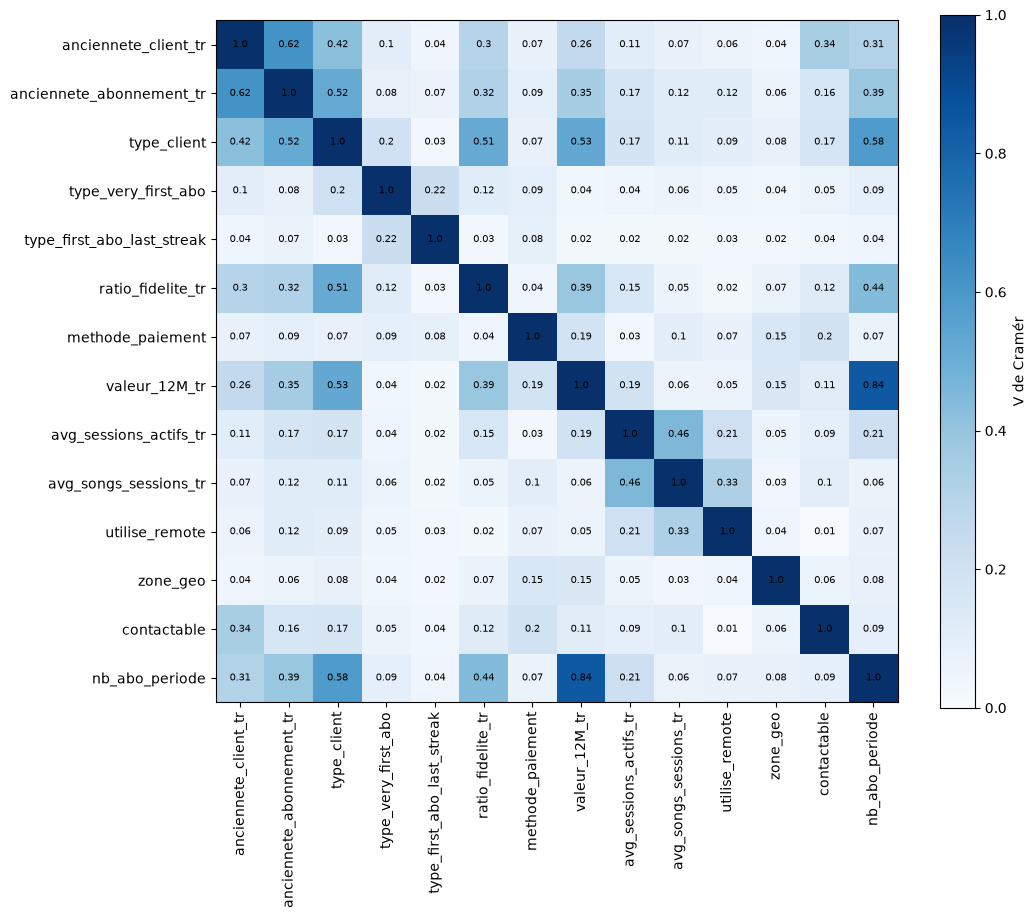

In [75]:
plt.figure(figsize=(11, 9))
plt.imshow(matrice2, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="V de Cramér")
plt.xticks(range(len(variables3)), variables3, rotation=90)
plt.yticks(range(len(variables3)), variables3)

for i in range(len(variables3)):
    for j in range(len(variables3)):
        plt.text(j, i, round(matrice2.iloc[i, j], 2), ha="center", va="center", fontsize=7)

plt.show()

In [76]:
couples = []
for i in range(len(variables3)):
    for j in range(i + 1, len(variables3)):
        v1 = variables3[i]
        v2 = variables3[j]
        couples.append([v1, v2, matrice.loc[v1, v2], matrice2.loc[v1, v2]])

comparaison = pd.DataFrame(couples, columns=["variable_1", "variable_2", "V_avant", "V_apres"])
comparaison["difference"] = comparaison["V_apres"] - comparaison["V_avant"]
comparaison = comparaison.sort_values("V_apres", ascending=False)
comparaison.round(2).head(20)

,variable_1,variable_2,V_avant,V_apres,difference
75,valeur_12M_tr,nb_abo_periode,0.63,0.84,0.21
0,anciennete_client_tr,anciennete_abonnement_tr,0.55,0.62,0.06
35,type_client,nb_abo_periode,0.59,0.58,-0.01
29,type_client,valeur_12M_tr,0.53,0.53,-0.01
13,anciennete_abonnement_tr,type_client,0.54,0.52,-0.02
27,type_client,ratio_fidelite_tr,0.51,0.51,-0.00
76,avg_sessions_actifs_tr,avg_songs_sessions_tr,0.30,0.46,0.16
62,ratio_fidelite_tr,nb_abo_periode,0.41,0.44,0.03
1,anciennete_client_tr,type_client,0.44,0.42,-0.02
24,anciennete_abonnement_tr,nb_abo_periode,0.29,0.39,0.10


In [77]:
comparaison.sort_values("difference").round(2).head(8)

,variable_1,variable_2,V_avant,V_apres,difference
47,type_first_abo_last_streak,methode_paiement,0.64,0.08,-0.56
4,anciennete_client_tr,ratio_fidelite_tr,0.50,0.30,-0.19
36,type_very_first_abo,type_first_abo_last_streak,0.35,0.22,-0.13
16,anciennete_abonnement_tr,ratio_fidelite_tr,0.40,0.32,-0.08
2,anciennete_client_tr,type_very_first_abo,0.13,0.10,-0.03
1,anciennete_client_tr,type_client,0.44,0.42,-0.02
13,anciennete_abonnement_tr,type_client,0.54,0.52,-0.02
21,anciennete_abonnement_tr,utilise_remote,0.14,0.12,-0.02


La plupart des V bougent peu (< 0,05).

Baisses :
- type_first_abo_last_streak / methode_paiement : 0,64 -> 0,08 (Credit fusionné)
- anciennete_client_tr / ratio_fidelite_tr : 0,50 -> 0,30
- type_very_first_abo / type_first_abo_last_streak : 0,35 -> 0,22

Hausses :
- valeur_12M_tr / nb_abo_periode : 0,63 -> 0,84, presque la même info
- sessions / chansons : 0,30 -> 0,46 (pas de session pèse plus)

Le V dépend du nombre de modalités donc la comparaison n'est pas parfaite.

type_first_abo_last_streak    0.03
methode_paiement              0.07
zone_geo                      0.08
utilise_remote                0.09
avg_songs_sessions_tr         0.11
contactable                   0.17
avg_sessions_actifs_tr        0.17
type_very_first_abo           0.20
anciennete_client_tr          0.42
ratio_fidelite_tr             0.51
anciennete_abonnement_tr      0.52
valeur_12M_tr                 0.53
nb_abo_periode                0.58
Name: type_client, dtype: float64


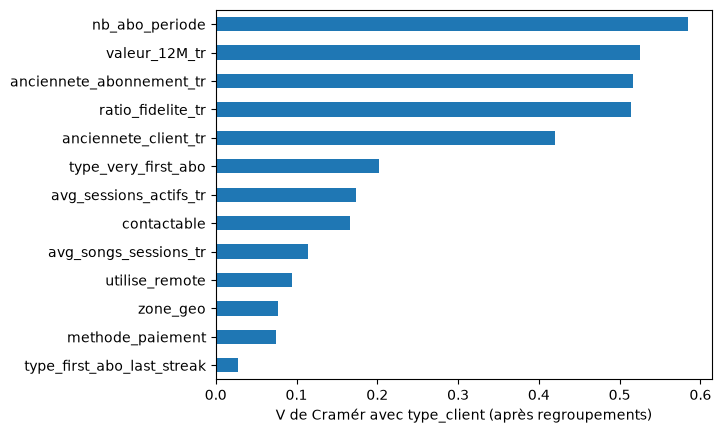

In [78]:
lien2 = matrice2["type_client"].drop("type_client").sort_values()
print(lien2.round(2))

lien2.plot(kind="barh")
plt.xlabel("V de Cramér avec type_client (après regroupements)")
plt.show()

Même classement qu'avant.

## 11. ACM de test

Première ACM pour vérifier les regroupements (comme le proc corresp mca benzecri du programme SAS), sur tous les clients.

Actives : les 11 variables restantes. Illustratives : type_client, contactable, type_first_abo_last_streak.

In [79]:
variables_actives = [
    "anciennete_client_tr",
    "anciennete_abonnement_tr",
    "type_very_first_abo",
    "ratio_fidelite_tr",
    "methode_paiement",
    "nb_abo_periode",
    "valeur_12M_tr",
    "avg_sessions_actifs_tr",
    "avg_songs_sessions_tr",
    "utilise_remote",
    "zone_geo",
]

variables_illustratives = ["type_client", "contactable", "type_first_abo_last_streak"]

In [80]:
Z = pd.get_dummies(df2[variables_actives], prefix_sep=" = ").astype(float)

n = len(Z)
Q = len(variables_actives)
J = Z.shape[1]

print(n, "clients,", Q, "variables,", J, "modalités")
Z.head()

341069 clients, 11 variables, 55 modalités


,anciennete_client_tr = 01_moins_3_mois,anciennete_client_tr = 02_3a5_mois,anciennete_client_tr = 03_6a12_mois,anciennete_client_tr = 04_13a24_mois,anciennete_client_tr = 05_25a48_mois,anciennete_client_tr = 06_49_mois_et_plus,anciennete_abonnement_tr = 01_moins_3_mois,anciennete_abonnement_tr = 02_3a5_mois,anciennete_abonnement_tr = 03_6a12_mois,anciennete_abonnement_tr = 04_13a24_mois,...,avg_songs_sessions_tr = 04_10a20,avg_songs_sessions_tr = 05_20_et_plus,utilise_remote = non,utilise_remote = oui,zone_geo = CA,zone_geo = Europe,zone_geo = FR,zone_geo = Reste_du_monde,zone_geo = UK,zone_geo = US
0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


### Calcul

Via le tableau de Burt. Vérif : inertie totale = J/Q - 1.

In [81]:
burt = Z.T @ Z

poids = Z.sum() / (n * Q)

matrice_acm = burt / (n * Q**2) - np.outer(poids, poids)
matrice_acm = matrice_acm / np.sqrt(np.outer(poids, poids))

valeurs, vecteurs = np.linalg.eigh(matrice_acm)

ordre = np.argsort(valeurs)[::-1]
valeurs = valeurs[ordre]
vecteurs = vecteurs[:, ordre]

nb_axes = J - Q
valeurs = valeurs[:nb_axes]
vecteurs = vecteurs[:, :nb_axes]

print("nombre d'axes :", nb_axes)
print("inertie totale :", valeurs.sum().round(4), "  (J / Q - 1 =", round(J / Q - 1, 4), ")")

nombre d'axes : 44
inertie totale : 4.0   (J / Q - 1 = 4.0 )


### Valeurs propres



In [82]:
axes = ["axe_" + str(k + 1) for k in range(nb_axes)]

valeurs_propres = pd.DataFrame({"valeur_propre": valeurs}, index=axes)
valeurs_propres["pct_inertie"] = valeurs / valeurs.sum() * 100
valeurs_propres["pct_cumule"] = valeurs_propres["pct_inertie"].cumsum()

corrigees = np.where(valeurs > 1 / Q, (Q / (Q - 1)) ** 2 * (valeurs - 1 / Q) ** 2, 0)
valeurs_propres["pct_benzecri"] = corrigees / corrigees.sum() * 100
valeurs_propres["pct_benzecri_cumule"] = valeurs_propres["pct_benzecri"].cumsum()

print("valeur propre moyenne (1/Q) :", round(1 / Q, 4))
valeurs_propres.round(3).head(15)

valeur propre moyenne (1/Q) : 0.0909


,valeur_propre,pct_inertie,pct_cumule,pct_benzecri,pct_benzecri_cumule
axe_1,0.330,8.261,8.261,46.969,46.969
axe_2,0.234,5.838,14.099,16.650,63.619
axe_3,0.204,5.094,19.193,10.423,74.042
axe_4,0.199,4.985,24.178,9.638,83.680
axe_5,0.179,4.485,28.663,6.411,90.091
axe_6,0.169,4.231,32.894,5.023,95.114
axe_7,0.135,3.371,36.266,1.581,96.695
axe_8,0.133,3.321,39.587,1.439,98.134
axe_9,0.121,3.024,42.610,0.739,98.873
axe_10,0.117,2.930,45.541,0.566,99.440


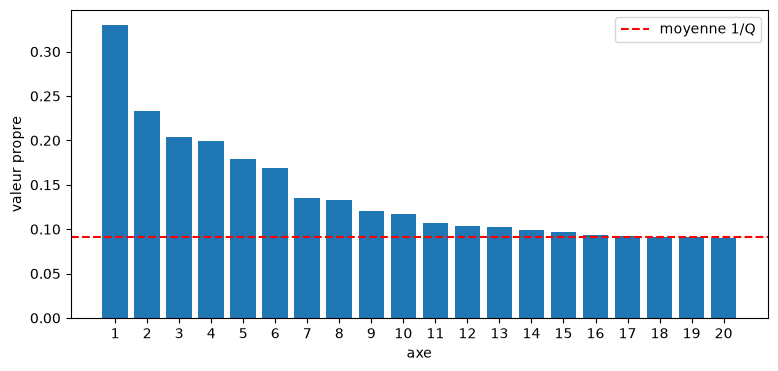

In [83]:
plt.figure(figsize=(9, 4))
plt.bar(range(1, 21), valeurs[:20])
plt.axhline(1 / Q, color="red", linestyle="--", label="moyenne 1/Q")
plt.xticks(range(1, 21))
plt.xlabel("axe")
plt.ylabel("valeur propre")
plt.legend()
plt.show()

Axe 1 = 47 %, cassure après l'axe 6 (95 % cumulé), donc 6 axes comme dans SAS.

### Contributions des variables

In [84]:
coord = pd.DataFrame(vecteurs * np.sqrt(valeurs), index=Z.columns, columns=axes)
coord = coord.div(np.sqrt(poids), axis=0)

contrib = pd.DataFrame(vecteurs**2 * 100, index=Z.columns, columns=axes)

frequence = Z.mean()
distance2 = 1 / frequence - 1
cos2 = (coord**2).div(distance2, axis=0)

print(contrib.sum().round(1).head(3))

axe_1    100.0
axe_2    100.0
axe_3    100.0
dtype: float64


In [85]:
variable_de_modalite = [nom.split(" = ")[0] for nom in Z.columns]
contrib_variables = contrib.groupby(variable_de_modalite).sum()

contrib_variables[["axe_1", "axe_2", "axe_3", "axe_4"]].round(1)

,axe_1,axe_2,axe_3,axe_4
anciennete_abonnement_tr,16.5,11.8,12.0,21.2
anciennete_client_tr,11.1,11.9,10.3,20.4
avg_sessions_actifs_tr,5.9,5.4,29.7,4.8
avg_songs_sessions_tr,0.5,2.0,29.6,4.8
methode_paiement,0.6,0.3,0.5,0.0
nb_abo_periode,24.4,27.9,2.3,20.0
ratio_fidelite_tr,15.5,12.8,9.3,9.8
type_very_first_abo,0.0,0.7,0.1,0.0
utilise_remote,0.1,0.7,4.2,0.2
valeur_12M_tr,24.1,26.3,2.0,18.2


In [86]:
nb_modalites = df2[variables_actives].nunique()
print(((nb_modalites - 1) / (J - Q) * 100).round(1))

anciennete_client_tr        11.4
anciennete_abonnement_tr     9.1
type_very_first_abo          2.3
ratio_fidelite_tr           11.4
methode_paiement             6.8
nb_abo_periode               9.1
valeur_12M_tr               13.6
avg_sessions_actifs_tr      11.4
avg_songs_sessions_tr       11.4
utilise_remote               2.3
zone_geo                    11.4
dtype: float64


Les variables en tranches pèsent entre 9 et 14 % chacune, ok.

Axes 1 et 2 : surtout nb_abo_periode et valeur_12M_tr (48 % et 54 %), normal vu le V de 0,84. Axe 3 : sessions et chansons (59 %). methode_paiement, zone_geo, type_very_first_abo et utilise_remote contribuent peu.

### Modalités qui construisent les axes

In [87]:
tableau = pd.DataFrame({
    "pct_clients": frequence * 100,
    "coordonnee": coord["axe_1"],
    "contribution": contrib["axe_1"],
    "cos2": cos2["axe_1"],
})
tableau.sort_values("contribution", ascending=False).round(2).head(12)

,pct_clients,coordonnee,contribution,cos2
nb_abo_periode = 05_12_abo,21.00,1.47,12.50,0.58
valeur_12M_tr = 01_moins_10,28.59,-1.10,9.43,0.48
nb_abo_periode = 01_1_abo,28.45,-1.09,9.37,0.48
anciennete_abonnement_tr = 05_25_mois_et_plus,12.12,1.51,7.59,0.31
valeur_12M_tr = 05_70a90,15.86,1.26,6.94,0.30
ratio_fidelite_tr = 01_moins_30,27.43,-0.90,6.07,0.30
ratio_fidelite_tr = 05_90_et_plus,36.12,0.72,5.19,0.30
valeur_12M_tr = 07_110_et_plus,6.81,1.65,5.12,0.20
anciennete_abonnement_tr = 04_13a24_mois,13.30,1.11,4.54,0.19
anciennete_client_tr = 01_moins_3_mois,10.44,-1.04,3.12,0.13


Axe 1 : engagement. À droite 12 abonnements, forte valeur, fidèles ; à gauche 1 abonnement, moins de 10 de valeur.

In [88]:
tableau = pd.DataFrame({
    "pct_clients": frequence * 100,
    "coordonnee": coord["axe_2"],
    "contribution": contrib["axe_2"],
    "cos2": cos2["axe_2"],
})
tableau.sort_values("contribution", ascending=False).round(2).head(12)

,pct_clients,coordonnee,contribution,cos2
nb_abo_periode = 03_4a6_abo,14.40,-1.49,12.43,0.37
valeur_12M_tr = 03_20a40,14.49,-1.37,10.62,0.32
nb_abo_periode = 01_1_abo,28.45,0.80,7.02,0.25
valeur_12M_tr = 01_moins_10,28.59,0.79,6.88,0.25
ratio_fidelite_tr = 99_vient_de_s_abonner,3.66,2.13,6.46,0.17
anciennete_abonnement_tr = 02_3a5_mois,15.45,-1.03,6.41,0.19
anciennete_client_tr = 01_moins_3_mois,10.44,1.21,5.92,0.17
nb_abo_periode = 05_12_abo,21.00,0.78,5.03,0.16
anciennete_client_tr = 02_3a5_mois,9.45,-1.10,4.45,0.13
valeur_12M_tr = 04_40a70,15.91,-0.76,3.58,0.11


Axe 2 : clients moyens (4-6 abonnements, 20-40 de valeur) contre les extrêmes. Effet Guttman (parabole), pas vraiment d'info en plus.

In [89]:
tableau = pd.DataFrame({
    "pct_clients": frequence * 100,
    "coordonnee": coord["axe_3"],
    "contribution": contrib["axe_3"],
    "cos2": cos2["axe_3"],
})
tableau.sort_values("contribution", ascending=False).round(2).head(12)

,pct_clients,coordonnee,contribution,cos2
avg_songs_sessions_tr = 00_pas_de_session,11.94,2.19,25.66,0.65
avg_sessions_actifs_tr = 00_pas_de_session,11.94,2.19,25.66,0.65
anciennete_abonnement_tr = 01_moins_3_mois,20.46,-0.93,7.96,0.22
anciennete_client_tr = 01_moins_3_mois,10.44,-1.30,7.83,0.20
ratio_fidelite_tr = 99_vient_de_s_abonner,3.66,-1.49,3.62,0.08
utilise_remote = oui,24.93,-0.53,3.12,0.09
ratio_fidelite_tr = 01_moins_30,27.43,0.50,3.09,0.10
anciennete_abonnement_tr = 04_13a24_mois,13.30,0.64,2.42,0.06
ratio_fidelite_tr = 05_90_et_plus,36.12,-0.37,2.24,0.08
anciennete_client_tr = 04_13a24_mois,18.45,0.45,1.69,0.05


Axe 3 : les clients sans session (51 % de l'axe), comptés deux fois.

### Modalités rares

Comparées à la contribution moyenne 100/J.

In [90]:
contribution_moyenne = 100 / J
print("contribution moyenne d'une modalité :", round(contribution_moyenne, 1))

rares = frequence[frequence < 0.05].index
tableau = contrib.loc[rares, axes[:6]].copy()
tableau.insert(0, "pct_clients", frequence[rares] * 100)
tableau.round(1)

contribution moyenne d'une modalité : 1.8


,pct_clients,axe_1,axe_2,axe_3,axe_4,axe_5,axe_6
type_very_first_abo = offert_reduc,3.1,0.0,0.7,0.1,0.0,0.2,0.0
ratio_fidelite_tr = 99_vient_de_s_abonner,3.7,2.5,6.5,3.6,2.3,0.8,8.4
valeur_12M_tr = 06_90a110,2.4,0.6,0.0,0.1,0.8,0.2,0.8


- 06_90a110 : sous la moyenne partout, ok
- offert_reduc : très faible
- vient_de_s_abonner : au-dessus sur certains axes (6,5 % axe 2, 8,4 % axe 6) mais ne fait pas un axe à elle seule

### Plan 1-2

In [91]:
coord_clients = (Z.values @ coord[["axe_1", "axe_2", "axe_3"]].values) / Q
coord_clients = coord_clients / np.sqrt(valeurs[:3])
coord_clients = pd.DataFrame(coord_clients, index=df2.index, columns=["axe_1", "axe_2", "axe_3"])

print(coord_clients.var(ddof=0).round(4))
print(valeurs[:3].round(4))

axe_1    0.3304
axe_2    0.2335
axe_3    0.2037
dtype: float64
[0.3304 0.2335 0.2037]


In [92]:
lignes = []
for var in variables_illustratives:
    moyennes = coord_clients.groupby(df2[var]).mean() / np.sqrt(valeurs[:3])
    moyennes.index = var + " = " + moyennes.index
    lignes.append(moyennes)

coord_illustratives = pd.concat(lignes)
coord_illustratives.round(2)

,axe_1,axe_2,axe_3
type_client = churn,-0.51,-0.15,0.42
type_client = nouveau,-0.36,0.01,-0.78
type_client = reactivated,0.16,-0.53,-0.41
type_client = retained,1.53,0.81,-0.13
contactable = non,0.13,0.11,0.09
contactable = oui,-0.09,-0.07,-0.06
type_first_abo_last_streak = offert_reduc,-0.08,-0.55,-0.17
type_first_abo_last_streak = payant,0.00,0.01,0.00


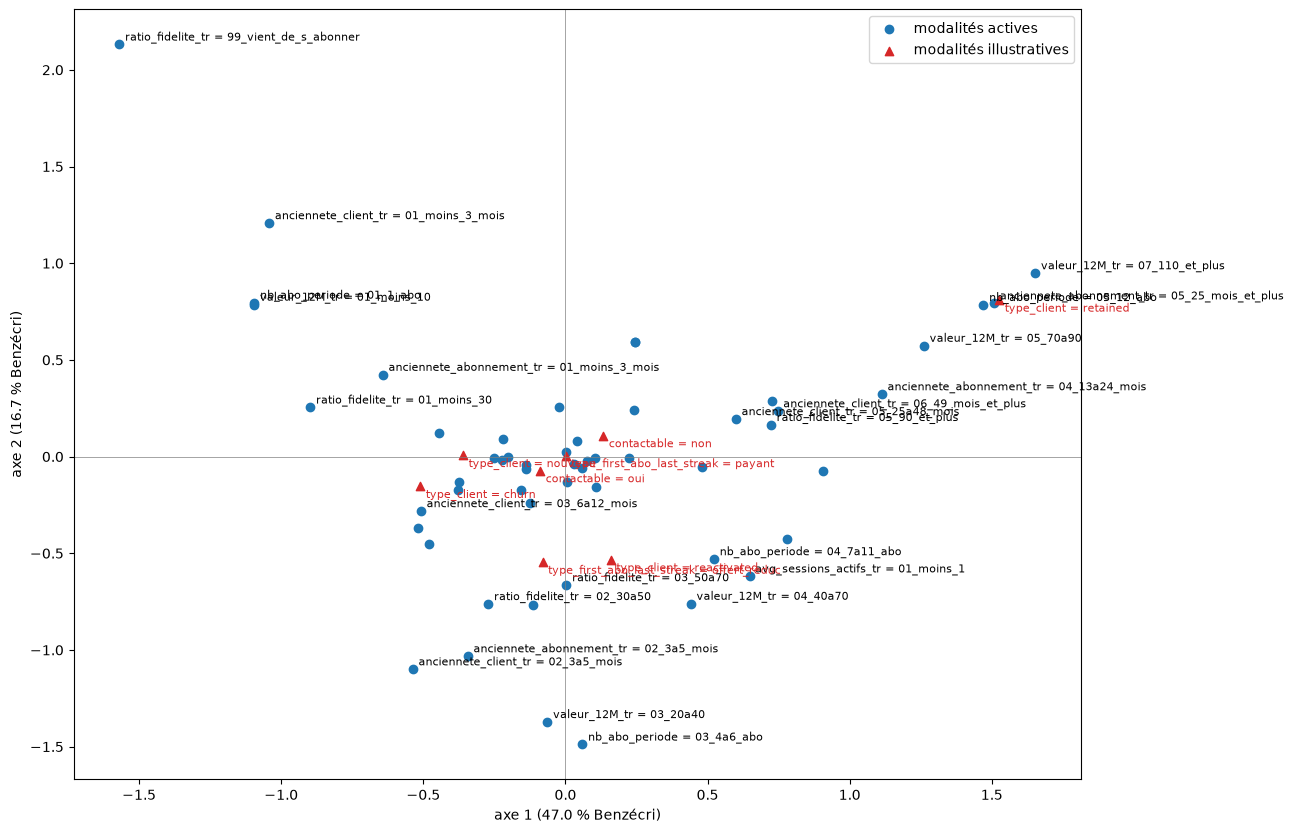

In [93]:
importantes = contrib.index[(contrib["axe_1"] > contribution_moyenne) | (contrib["axe_2"] > contribution_moyenne)]

plt.figure(figsize=(13, 10))
plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)

plt.scatter(coord["axe_1"], coord["axe_2"], color="tab:blue", label="modalités actives")
for nom in importantes:
    plt.text(coord.loc[nom, "axe_1"] + 0.02, coord.loc[nom, "axe_2"] + 0.02, nom, fontsize=8)

plt.scatter(coord_illustratives["axe_1"], coord_illustratives["axe_2"], color="tab:red", marker="^", label="modalités illustratives")
for nom in coord_illustratives.index:
    plt.text(coord_illustratives.loc[nom, "axe_1"] + 0.02, coord_illustratives.loc[nom, "axe_2"] - 0.06, nom, fontsize=8, color="tab:red")

plt.xlabel("axe 1 (" + str(round(valeurs_propres.loc["axe_1", "pct_benzecri"], 1)) + " % Benzécri)")
plt.ylabel("axe 2 (" + str(round(valeurs_propres.loc["axe_2", "pct_benzecri"], 1)) + " % Benzécri)")
plt.legend()
plt.show()

On voit la parabole. retained à droite (1,53), churn et nouveau à gauche, contactable au centre.

## 12. Bilan

Ok : pas d'axe créé par une modalité rare, pas de variable qui écrase les autres, axe 1 interprétable, 6 axes = 95 %.

À revoir pour l'ACM finale :
- valeur_12M_tr et nb_abo_periode presque redondantes (V = 0,84), en mettre une en illustrative ?
- pas de session dans deux variables -> axe 3
- axe 2 = effet Guttman

## 13. ACM sur un échantillon de 20 %

On tire 20 % des clients au hasard dans df2 et on refait l'ACM dessus.

In [94]:
ech = df2.sample(frac=0.2, random_state=1).copy()
print(len(ech))

68214


In [95]:
ecarts_ech = []
for var in variables_actives + variables_illustratives:
    difference = df2[var].value_counts(normalize=True) - ech[var].value_counts(normalize=True)
    ecarts_ech.append([var, difference.abs().max() * 100])

pd.DataFrame(ecarts_ech, columns=["variable", "ecart_max_pct"]).round(2)

,variable,ecart_max_pct
0,anciennete_client_tr,0.21
1,anciennete_abonnement_tr,0.24
2,type_very_first_abo,0.07
3,ratio_fidelite_tr,0.31
4,methode_paiement,0.20
5,nb_abo_periode,0.31
6,valeur_12M_tr,0.30
7,avg_sessions_actifs_tr,0.25
8,avg_songs_sessions_tr,0.19
9,utilise_remote,0.08


68 214 clients. Pour toutes les variables, les % des modalités sont à moins de 0,3 point de ceux de la base complète : l'échantillon est représentatif.

### 13.1 Fonctions

Même calcul que dans la partie 11, mis dans une fonction pour pouvoir refaire l'ACM après les changements.

In [96]:
def acm(data, actives):
    Z = pd.get_dummies(data[actives], prefix_sep=" = ").astype(float)
    n = len(Z)
    Q = len(actives)
    J = Z.shape[1]

    poids = Z.sum() / (n * Q)
    m = (Z.T @ Z) / (n * Q**2) - np.outer(poids, poids)
    m = m / np.sqrt(np.outer(poids, poids))

    valeurs, vecteurs = np.linalg.eigh(m)
    ordre = np.argsort(valeurs)[::-1][:J - Q]
    valeurs = valeurs[ordre]
    vecteurs = vecteurs[:, ordre]
    axes = ["axe_" + str(k + 1) for k in range(J - Q)]

    vp = pd.DataFrame({"valeur_propre": valeurs}, index=axes)
    vp["pct_inertie"] = valeurs / valeurs.sum() * 100
    corrigees = np.where(valeurs > 1 / Q, (Q / (Q - 1)) ** 2 * (valeurs - 1 / Q) ** 2, 0)
    vp["pct_benzecri"] = corrigees / corrigees.sum() * 100
    vp["pct_benzecri_cumule"] = vp["pct_benzecri"].cumsum()

    coord = pd.DataFrame(vecteurs * np.sqrt(valeurs), index=Z.columns, columns=axes)
    coord = coord.div(np.sqrt(poids), axis=0)
    contrib = pd.DataFrame(vecteurs**2 * 100, index=Z.columns, columns=axes)
    frequence = Z.mean()
    cos2 = (coord**2).div(1 / frequence - 1, axis=0)

    return {"Z": Z, "Q": Q, "J": J, "valeurs": valeurs, "vp": vp,
            "coord": coord, "contrib": contrib, "cos2": cos2, "frequence": frequence}

In [97]:
def axes_gardes(res):
    return (res["vp"]["pct_benzecri_cumule"] < 95).sum() + 1


def contributions_variables(res):
    nb = axes_gardes(res)
    axes = res["contrib"].columns[:nb]
    variable_de_modalite = [nom.split(" = ")[0] for nom in res["contrib"].index]
    somme = res["contrib"][axes].groupby(variable_de_modalite).sum()
    au_dessus = (res["contrib"][axes] > 100 / res["J"]).groupby(variable_de_modalite).sum()
    somme["nb_modalites_au_dessus"] = au_dessus.sum(axis=1)
    return somme.sort_values("nb_modalites_au_dessus")


def modalites_axe(res, axe):
    tableau = pd.DataFrame({
        "pct_clients": res["frequence"] * 100,
        "coordonnee": res["coord"][axe],
        "contribution": res["contrib"][axe],
        "cos2": res["cos2"][axe],
    })
    tableau = tableau[tableau["contribution"] > 100 / res["J"]]
    return tableau.sort_values("coordonnee")


def distances_voisines(res, actives):
    nb = axes_gardes(res)
    coord = res["coord"].iloc[:, :nb]
    lignes = []
    for var in actives:
        modalites = sorted([m for m in coord.index if m.startswith(var + " = ")])
        for i in range(len(modalites) - 1):
            d = np.sqrt(((coord.loc[modalites[i]] - coord.loc[modalites[i + 1]]) ** 2).sum())
            lignes.append([var, modalites[i].split(" = ")[1], modalites[i + 1].split(" = ")[1], d])
    return pd.DataFrame(lignes, columns=["variable", "modalite_1", "modalite_2", "distance"])


def coord_illustratives(res, data, illustratives, nb=4):
    clients = (res["Z"].values @ res["coord"].iloc[:, :nb].values) / res["Q"]
    clients = clients / np.sqrt(res["valeurs"][:nb])
    clients = pd.DataFrame(clients, index=data.index, columns=res["coord"].columns[:nb])
    lignes = []
    for var in illustratives:
        moyennes = clients.groupby(data[var]).mean() / np.sqrt(res["valeurs"][:nb])
        moyennes.index = var + " = " + moyennes.index
        lignes.append(moyennes)
    return pd.concat(lignes)


def plan(res, illus, axe_x, axe_y):
    coord = res["coord"]
    contrib = res["contrib"]
    moyenne = 100 / res["J"]
    importantes = contrib.index[(contrib[axe_x] > moyenne) | (contrib[axe_y] > moyenne)]

    plt.figure(figsize=(13, 10))
    plt.axhline(0, color="grey", linewidth=0.5)
    plt.axvline(0, color="grey", linewidth=0.5)
    plt.scatter(coord[axe_x], coord[axe_y], color="tab:blue", label="modalités actives")
    for nom in importantes:
        plt.text(coord.loc[nom, axe_x] + 0.02, coord.loc[nom, axe_y] + 0.02, nom, fontsize=8)
    plt.scatter(illus[axe_x], illus[axe_y], color="tab:red", marker="^", label="modalités illustratives")
    for nom in illus.index:
        plt.text(illus.loc[nom, axe_x] + 0.02, illus.loc[nom, axe_y] - 0.06, nom, fontsize=7, color="tab:red")
    plt.xlabel(axe_x + " (" + str(round(res["vp"].loc[axe_x, "pct_benzecri"], 1)) + " % Benzécri)")
    plt.ylabel(axe_y + " (" + str(round(res["vp"].loc[axe_y, "pct_benzecri"], 1)) + " % Benzécri)")
    plt.legend()
    plt.show()

### 13.2 ACM 1 : les 11 variables actives

In [98]:
res1 = acm(ech, variables_actives)
print("axes gardés (95 % Benzécri) :", axes_gardes(res1))
res1["vp"].round(3).head(10)

axes gardés (95 % Benzécri) : 6


,valeur_propre,pct_inertie,pct_benzecri,pct_benzecri_cumule
axe_1,0.330,8.260,46.889,46.889
axe_2,0.234,5.848,16.722,63.611
axe_3,0.205,5.118,10.592,74.203
axe_4,0.199,4.972,9.528,83.731
axe_5,0.179,4.471,6.319,90.050
axe_6,0.170,4.246,5.093,95.143
axe_7,0.134,3.361,1.550,96.693
axe_8,0.133,3.315,1.421,98.114
axe_9,0.121,3.035,0.760,98.874
axe_10,0.117,2.932,0.569,99.443


Presque pareil que sur toute la base (partie 11) : axe 1 = 47 % Benzécri, 6 axes pour arriver à 95 %. On travaille sur ces 6 axes.

### 13.3 Analyse des axes

Pour chaque axe, les modalités qui contribuent plus que la moyenne (100 / J), triées par coordonnée. Les modalités du même côté et proches sont celles qui vont ensemble.

In [99]:
modalites_axe(res1, "axe_1").round(2)

,pct_clients,coordonnee,contribution,cos2
ratio_fidelite_tr = 99_vient_de_s_abonner,3.68,-1.56,2.45,0.09
valeur_12M_tr = 01_moins_10,28.90,-1.09,9.41,0.48
nb_abo_periode = 01_1_abo,28.76,-1.09,9.35,0.48
anciennete_client_tr = 01_moins_3_mois,10.49,-1.03,3.08,0.12
ratio_fidelite_tr = 01_moins_30,27.69,-0.89,6.09,0.31
anciennete_abonnement_tr = 01_moins_3_mois,20.44,-0.64,2.28,0.10
anciennete_client_tr = 03_6a12_mois,28.66,-0.51,2.08,0.11
anciennete_client_tr = 05_25a48_mois,18.68,0.60,1.83,0.08
avg_sessions_actifs_tr = 01_moins_1,19.81,0.65,2.29,0.10
ratio_fidelite_tr = 05_90_et_plus,35.81,0.72,5.16,0.29


Axe 1 : engagement.

- à gauche, des modalités proches entre elles : 1 abonnement et moins de 10 de valeur (même point, -1,09), ratio < 30, client depuis moins de 3 mois, vient de s'abonner
- à droite : 12 abonnements, valeur 70-90 et 110+, abonnement de plus de 13 mois, ratio 90+, clients de plus de 25 mois

01_1_abo et 01_moins_10 sont au même endroit : ce sont quasiment les mêmes clients.

In [100]:
modalites_axe(res1, "axe_2").round(2)

,pct_clients,coordonnee,contribution,cos2
ratio_fidelite_tr = 99_vient_de_s_abonner,3.68,-2.11,6.37,0.17
anciennete_client_tr = 01_moins_3_mois,10.49,-1.20,5.88,0.17
valeur_12M_tr = 07_110_et_plus,6.77,-0.95,2.39,0.07
anciennete_abonnement_tr = 05_25_mois_et_plus,12.27,-0.79,3.01,0.09
nb_abo_periode = 01_1_abo,28.76,-0.79,6.99,0.25
nb_abo_periode = 05_12_abo,20.88,-0.79,5.04,0.16
valeur_12M_tr = 01_moins_10,28.90,-0.78,6.83,0.25
valeur_12M_tr = 05_70a90,15.72,-0.58,2.04,0.06
nb_abo_periode = 04_7a11_abo,16.62,0.55,1.94,0.06
avg_sessions_actifs_tr = 01_moins_1,19.81,0.63,3.10,0.10


Axe 2 : clients intermédiaires (4-6 abonnements, valeur 20-40, abonnement de 3-5 mois, ratio 30-70) contre les deux extrêmes (1 abo et 12 abo à -0,79 tous les deux) et les nouveaux (vient_de_s_abonner à -2,11). C'est l'effet Guttman vu dans la partie 11.

In [101]:
modalites_axe(res1, "axe_3").round(2)

,pct_clients,coordonnee,contribution,cos2
avg_songs_sessions_tr = 00_pas_de_session,12.02,-2.08,23.14,0.59
avg_sessions_actifs_tr = 00_pas_de_session,12.02,-2.08,23.14,0.59
anciennete_abonnement_tr = 04_13a24_mois,13.06,-0.61,2.18,0.06
ratio_fidelite_tr = 01_moins_30,27.69,-0.55,3.75,0.12
anciennete_abonnement_tr = 03_6a12_mois,38.64,-0.35,2.12,0.08
ratio_fidelite_tr = 05_90_et_plus,35.81,0.38,2.29,0.08
utilise_remote = oui,25.01,0.53,3.12,0.09
anciennete_abonnement_tr = 01_moins_3_mois,20.44,1.02,9.38,0.27
anciennete_client_tr = 01_moins_3_mois,10.49,1.42,9.43,0.24
ratio_fidelite_tr = 99_vient_de_s_abonner,3.68,1.62,4.27,0.10


Axe 3 : les deux pas_de_session (-2,08) font 46 % de l'axe à elles deux, contre les clients récents (moins de 3 mois, vient de s'abonner). Elles ont exactement la même coordonnée : ce sont les mêmes clients comptés deux fois.

In [102]:
modalites_axe(res1, "axe_4").round(2)

,pct_clients,coordonnee,contribution,cos2
anciennete_client_tr = 01_moins_3_mois,10.49,-1.10,5.84,0.14
avg_songs_sessions_tr = 00_pas_de_session,12.02,-1.07,6.26,0.16
avg_sessions_actifs_tr = 00_pas_de_session,12.02,-1.07,6.26,0.16
anciennete_client_tr = 02_3a5_mois,9.50,-0.92,3.66,0.09
valeur_12M_tr = 03_20a40,14.43,-0.87,5.04,0.13
nb_abo_periode = 02_2a3_abo,19.34,-0.83,6.07,0.16
valeur_12M_tr = 02_10a20,15.85,-0.80,4.68,0.12
anciennete_abonnement_tr = 01_moins_3_mois,20.44,-0.71,4.76,0.13
nb_abo_periode = 03_4a6_abo,14.39,-0.66,2.83,0.07
ratio_fidelite_tr = 02_30a50,11.52,-0.59,1.84,0.05


Axe 4 : 2-6 abonnements / 3-5 mois d'ancienneté contre 7-11 abonnements / 6-12 mois. Il coupe en deux le milieu de l'axe 1. On retrouve aussi pas_de_session.

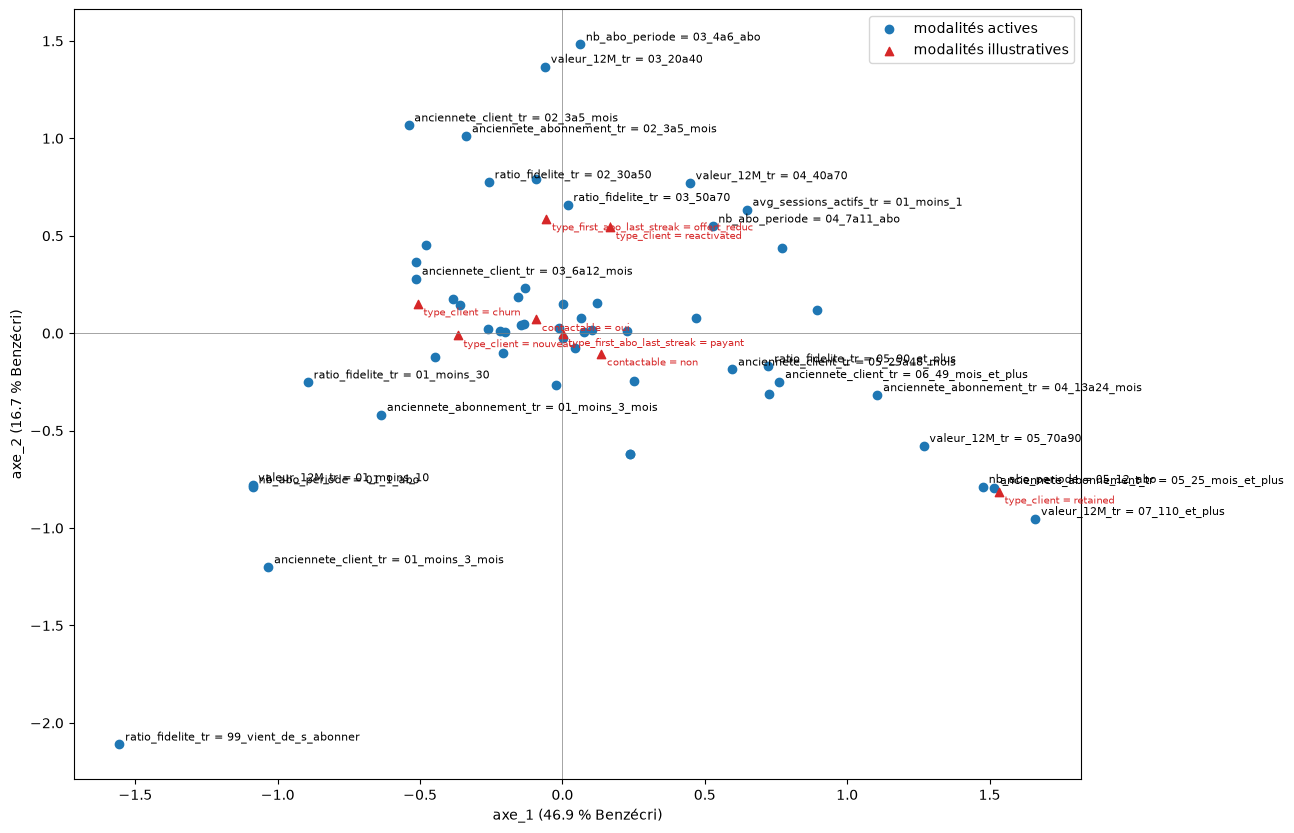

In [103]:
illus1 = coord_illustratives(res1, ech, variables_illustratives)
plan(res1, illus1, "axe_1", "axe_2")

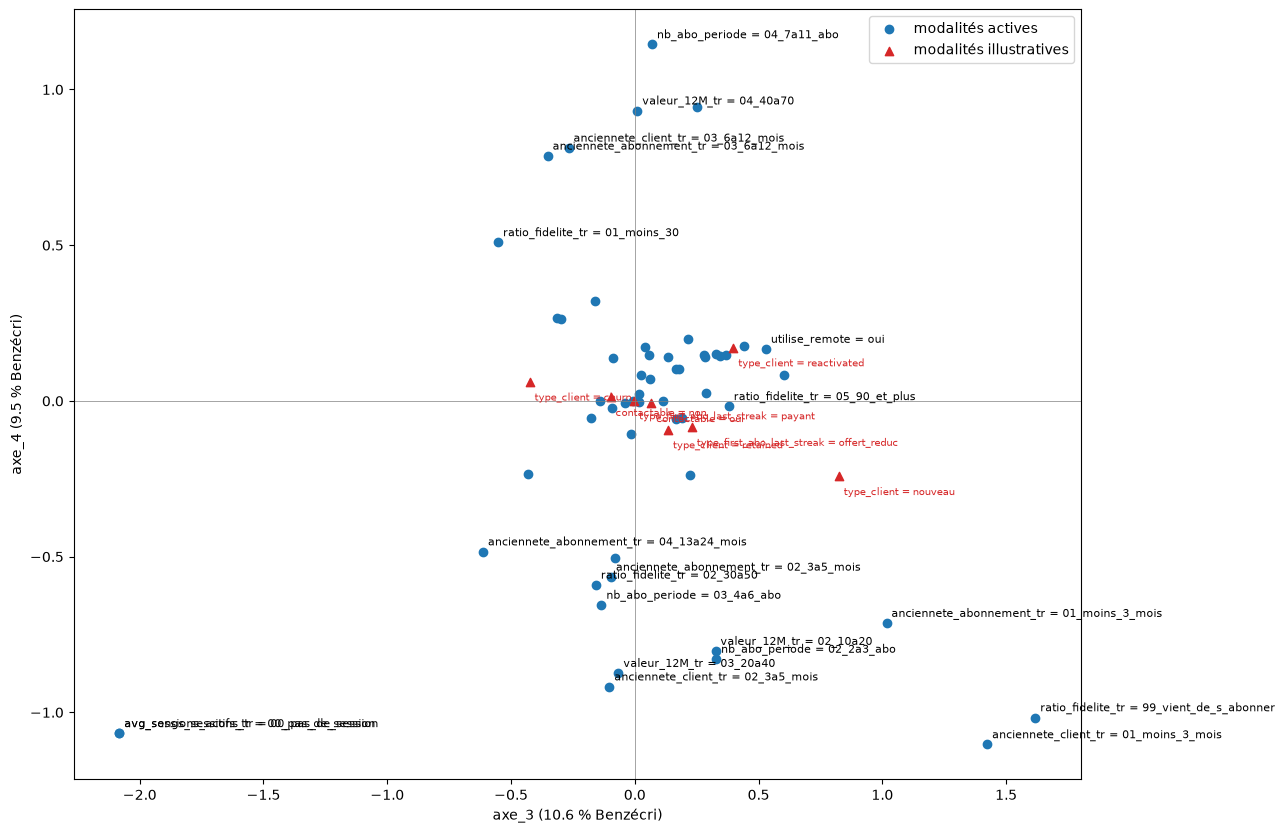

In [104]:
plan(res1, illus1, "axe_3", "axe_4")

Plan 1-2 : la parabole, avec retained tout à droite à côté de 12 abonnements et de l'abonnement de plus de 25 mois. churn et nouveau sont à gauche, contactable au centre.

Plan 3-4 : les deux pas_de_session sont superposées en bas à gauche. Côté usage, à part pas_de_session, seule utilise_remote = oui sort un peu (axe 3).

### 13.4 Autres regroupements ?

Distance entre deux modalités voisines d'une même variable, sur les axes gardés. Une petite distance veut dire que les deux modalités sont au même endroit sur tous les axes, on peut les fusionner sans perdre d'info.

In [105]:
distances1 = distances_voisines(res1, variables_actives)
distances1.sort_values("distance").round(2).head(15)

,variable,modalite_1,modalite_2,distance
35,avg_songs_sessions_tr,02_3a6,03_6a10,0.12
36,avg_songs_sessions_tr,03_6a10,04_10a20,0.15
37,avg_songs_sessions_tr,04_10a20,05_20_et_plus,0.19
40,zone_geo,Europe,FR,0.19
41,zone_geo,FR,Reste_du_monde,0.26
39,zone_geo,CA,Europe,0.28
15,methode_paiement,Android,Apple,0.30
30,avg_sessions_actifs_tr,02_1a2,03_2a5,0.33
4,anciennete_client_tr,05_25a48_mois,06_49_mois_et_plus,0.35
34,avg_songs_sessions_tr,01_1a3,02_3a6,0.38


Les modalités les plus proches :

- avg_songs_sessions_tr : toutes les tranches à partir de 1-3 sont au même endroit (0,12 à 0,38). La variable ne sépare en fait que pas de session / le reste, ce que fait déjà avg_sessions_actifs_tr.
- zone_geo et methode_paiement : toutes les modalités sont proches (moins de 0,65), les variables ne servent à rien sur les axes (voir 13.5).
- avg_sessions_actifs_tr 1-2 / 2-5 (0,33) : on fusionne en 1-5.
- anciennete_client_tr 25-48 / 49+ (0,35) : on fusionne en 25 et plus.

Les autres variables (nb_abo_periode, valeur_12M_tr, anciennete_abonnement_tr, ratio_fidelite_tr) ont des modalités voisines bien séparées (plus de 1), on n'y touche pas.

In [106]:
ech["anciennete_client_tr"] = ech["anciennete_client_tr"].replace({
    "05_25a48_mois": "05_25_mois_et_plus",
    "06_49_mois_et_plus": "05_25_mois_et_plus",
})
ech["avg_sessions_actifs_tr"] = ech["avg_sessions_actifs_tr"].replace({
    "02_1a2": "02_1a5",
    "03_2a5": "02_1a5",
})

for var in ["anciennete_client_tr", "avg_sessions_actifs_tr"]:
    print((ech[var].value_counts(normalize=True).sort_index() * 100).round(1))
    print()

anciennete_client_tr
01_moins_3_mois       10.5
02_3a5_mois            9.5
03_6a12_mois          28.7
04_13a24_mois         18.4
05_25_mois_et_plus    32.9
Name: proportion, dtype: float64

avg_sessions_actifs_tr
00_pas_de_session    12.0
01_moins_1           19.8
02_1a5               50.4
04_5a10              10.6
05_10_et_plus         7.2
Name: proportion, dtype: float64



### 13.5 Variables qui ne contribuent pas aux axes

Pour chaque variable : somme des contributions de ses modalités sur les axes gardés, et nombre de fois où une de ses modalités dépasse la contribution moyenne. Si ce nombre vaut 0, la variable ne construit aucun axe, on la passe en illustrative.

In [107]:
contributions_variables(res1).round(1)

,axe_1,axe_2,axe_3,axe_4,axe_5,axe_6,nb_modalites_au_dessus
type_very_first_abo,0.0,0.8,0.1,0.0,0.2,0.0,0
methode_paiement,0.6,0.3,0.5,0.0,0.0,1.5,0
zone_geo,1.3,0.2,0.0,0.4,0.1,0.9,0
utilise_remote,0.2,0.7,4.2,0.4,0.0,0.1,1
avg_songs_sessions_tr,0.5,2.2,26.8,7.1,1.4,3.2,3
avg_sessions_actifs_tr,5.9,5.8,26.9,7.2,1.9,4.4,5
anciennete_client_tr,11.2,11.6,12.1,18.7,15.8,11.8,12
ratio_fidelite_tr,15.5,12.8,10.6,8.7,2.4,21.0,14
anciennete_abonnement_tr,16.5,11.6,13.9,19.4,15.1,11.1,15
nb_abo_periode,24.4,27.8,2.6,19.8,33.1,22.8,16


- type_very_first_abo, methode_paiement, zone_geo : aucune modalité au-dessus de la moyenne sur les 6 axes, moins de 1,5 % de contribution partout → exclues (en illustratives).
- avg_songs_sessions_tr : elle contribue, mais uniquement par pas_de_session, qui est la même chose que dans avg_sessions_actifs_tr. Ses autres modalités sont collées (13.4). On l'exclut aussi pour ne pas compter deux fois les clients sans session.
- utilise_remote : 1 modalité au-dessus (axe 3), on la garde pour l'instant.

In [108]:
exclues1 = ["methode_paiement", "zone_geo", "type_very_first_abo", "avg_songs_sessions_tr"]
actives2 = [v for v in variables_actives if v not in exclues1]
illustratives2 = variables_illustratives + exclues1
print(actives2)

['anciennete_client_tr', 'anciennete_abonnement_tr', 'ratio_fidelite_tr', 'nb_abo_periode', 'valeur_12M_tr', 'avg_sessions_actifs_tr', 'utilise_remote']


### 13.6 ACM 2 : après regroupements et exclusions

In [109]:
res2 = acm(ech, actives2)
print("axes gardés (95 % Benzécri) :", axes_gardes(res2))
res2["vp"].round(3).head(8)

axes gardés (95 % Benzécri) : 5


,valeur_propre,pct_inertie,pct_benzecri,pct_benzecri_cumule
axe_1,0.510,12.740,52.245,52.245
axe_2,0.362,9.040,18.585,70.829
axe_3,0.314,7.841,11.331,82.160
axe_4,0.282,7.045,7.497,89.657
axe_5,0.270,6.754,6.296,95.953
axe_6,0.225,5.626,2.623,98.577
axe_7,0.193,4.818,0.966,99.543
axe_8,0.176,4.407,0.433,99.976


In [110]:
contributions_variables(res2).round(1)

,axe_1,axe_2,axe_3,axe_4,axe_5,nb_modalites_au_dessus
avg_sessions_actifs_tr,6.0,3.7,0.2,1.3,2.3,0
utilise_remote,0.1,0.2,0.2,0.2,0.7,0
anciennete_client_tr,11.3,13.7,24.6,17.9,7.8,8
anciennete_abonnement_tr,16.5,13.0,26.2,17.4,7.8,9
ratio_fidelite_tr,16.0,14.4,14.6,1.4,22.9,10
nb_abo_periode,25.2,28.1,17.8,33.0,29.2,13
valeur_12M_tr,24.8,26.7,16.4,28.8,29.2,15


Une fois avg_songs_sessions_tr enlevée, les variables d'usage ne contribuent plus : avg_sessions_actifs_tr et utilise_remote n'ont plus aucune modalité au-dessus de la moyenne sur les 5 axes gardés. Leur contribution dans l'ACM 1 venait du doublon pas_de_session. On les passe en illustratives.

In [111]:
exclues2 = ["utilise_remote", "avg_sessions_actifs_tr"]
actives3 = [v for v in actives2 if v not in exclues2]
illustratives3 = illustratives2 + exclues2
print(actives3)

['anciennete_client_tr', 'anciennete_abonnement_tr', 'ratio_fidelite_tr', 'nb_abo_periode', 'valeur_12M_tr']


### 13.7 ACM 3 : variables finales

In [112]:
res3 = acm(ech, actives3)
print("axes gardés (95 % Benzécri) :", axes_gardes(res3))
res3["vp"].round(3).head(8)

axes gardés (95 % Benzécri) : 5


,valeur_propre,pct_inertie,pct_benzecri,pct_benzecri_cumule
axe_1,0.681,14.796,50.703,50.703
axe_2,0.493,10.725,18.889,69.592
axe_3,0.438,9.527,12.459,82.051
axe_4,0.392,8.514,8.062,90.113
axe_5,0.372,8.093,6.516,96.629
axe_6,0.303,6.593,2.342,98.971
axe_7,0.266,5.782,0.955,99.926
axe_8,0.218,4.747,0.074,100.000


In [113]:
contributions_variables(res3).round(1)

,axe_1,axe_2,axe_3,axe_4,axe_5,nb_modalites_au_dessus
anciennete_abonnement_tr,18.2,13.7,26.1,14.6,9.3,7
anciennete_client_tr,12.4,15.6,24.7,15.4,8.8,7
ratio_fidelite_tr,16.5,15.9,14.5,2.2,23.9,8
valeur_12M_tr,26.2,26.7,16.7,32.1,28.8,12
nb_abo_periode,26.7,28.1,18.1,35.8,29.2,13


In [114]:
distances_voisines(res3, actives3).sort_values("distance").round(2).head(8)

,variable,modalite_1,modalite_2,distance
3,anciennete_client_tr,04_13a24_mois,05_25_mois_et_plus,0.54
7,anciennete_abonnement_tr,04_13a24_mois,05_25_mois_et_plus,0.93
11,ratio_fidelite_tr,04_70a90,05_90_et_plus,1.12
9,ratio_fidelite_tr,02_30a50,03_50a70,1.13
10,ratio_fidelite_tr,03_50a70,04_70a90,1.20
2,anciennete_client_tr,03_6a12_mois,04_13a24_mois,1.33
8,ratio_fidelite_tr,01_moins_30,02_30a50,1.78
21,valeur_12M_tr,05_70a90,06_90a110,1.83


5 variables actives, 5 axes pour 95 %. Toutes les variables contribuent (au moins 7 modalités au-dessus de la moyenne).

La paire la plus proche est anciennete_client_tr 13-24 / 25+ (0,54), mais 13-24 fait 18 % des clients : pas besoin de fusionner.

In [115]:
modalites_axe(res3, "axe_1").round(2)

,pct_clients,coordonnee,contribution,cos2
valeur_12M_tr = 01_moins_10,28.90,-1.07,9.70,0.46
nb_abo_periode = 01_1_abo,28.76,-1.07,9.62,0.46
ratio_fidelite_tr = 01_moins_30,27.69,-0.87,6.20,0.29
anciennete_client_tr = 05_25_mois_et_plus,32.94,0.70,4.68,0.24
ratio_fidelite_tr = 05_90_et_plus,35.81,0.74,5.71,0.30
anciennete_abonnement_tr = 04_13a24_mois,13.06,1.10,4.66,0.18
valeur_12M_tr = 05_70a90,15.72,1.36,8.49,0.34
nb_abo_periode = 05_12_abo,20.88,1.54,14.48,0.62
anciennete_abonnement_tr = 05_25_mois_et_plus,12.27,1.56,8.80,0.34
valeur_12M_tr = 07_110_et_plus,6.77,1.64,5.37,0.20


In [116]:
modalites_axe(res3, "axe_2").round(2)

,pct_clients,coordonnee,contribution,cos2
nb_abo_periode = 03_4a6_abo,14.39,-1.57,14.36,0.41
valeur_12M_tr = 03_20a40,14.43,-1.46,12.43,0.36
anciennete_client_tr = 02_3a5_mois,9.50,-1.24,5.96,0.16
anciennete_abonnement_tr = 02_3a5_mois,15.59,-1.13,8.03,0.23
nb_abo_periode = 05_12_abo,20.88,0.74,4.58,0.14
valeur_12M_tr = 01_moins_10,28.90,0.76,6.69,0.23
nb_abo_periode = 01_1_abo,28.76,0.76,6.74,0.23
anciennete_client_tr = 01_moins_3_mois,10.49,1.42,8.59,0.24
ratio_fidelite_tr = 99_vient_de_s_abonner,3.68,2.40,8.59,0.22


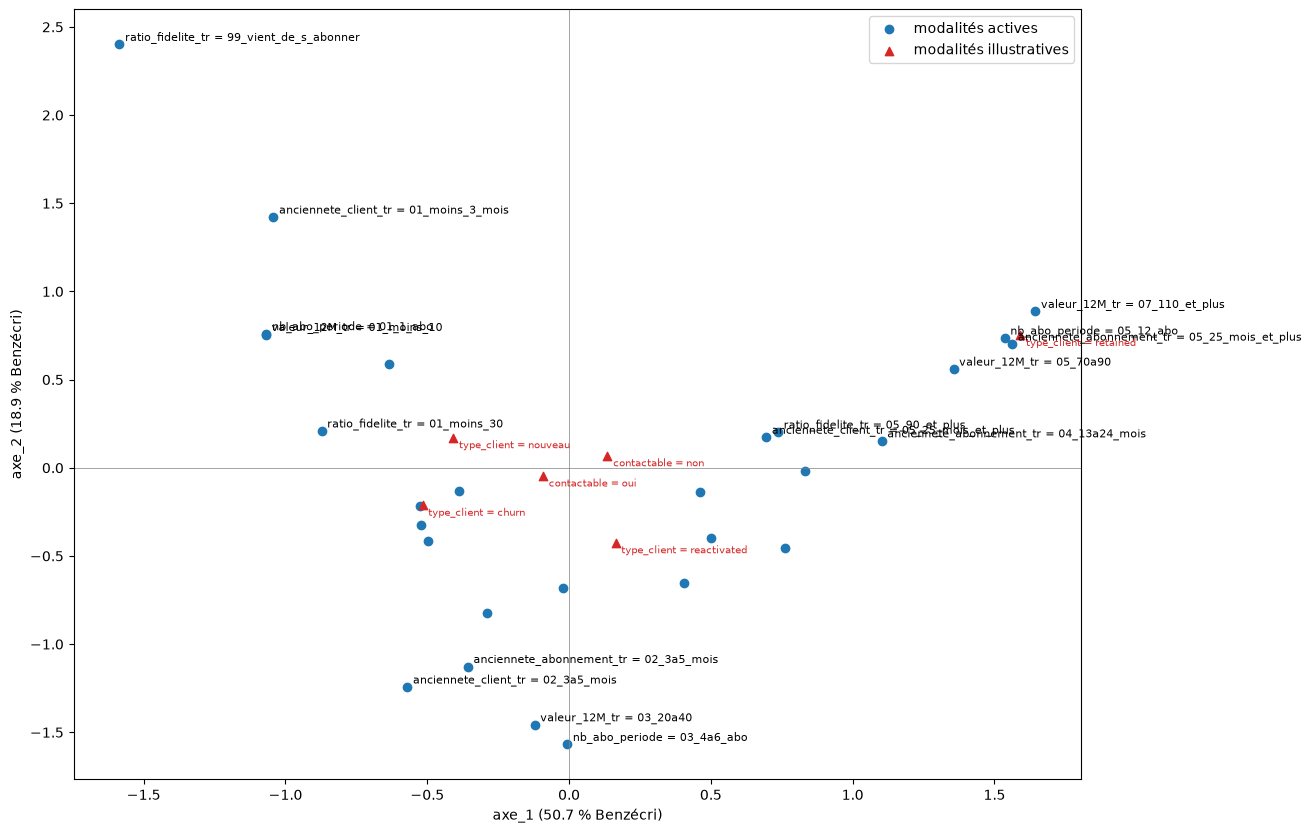

In [117]:
illus3 = coord_illustratives(res3, ech, illustratives3)
a_afficher = [nom for nom in illus3.index if nom.startswith("type_client") or nom.startswith("contactable")]
plan(res3, illus3.loc[a_afficher], "axe_1", "axe_2")

In [118]:
illus3[["axe_1", "axe_2"]].round(2).sort_values("axe_1")

,axe_1,axe_2
type_client = churn,-0.52,-0.21
type_client = nouveau,-0.41,0.17
avg_sessions_actifs_tr = 02_1a5,-0.30,0.05
zone_geo = FR,-0.19,-0.01
avg_songs_sessions_tr = 01_1a3,-0.17,0.04
zone_geo = Europe,-0.15,0.05
zone_geo = Reste_du_monde,-0.15,-0.00
methode_paiement = Apple,-0.12,-0.04
avg_songs_sessions_tr = 05_20_et_plus,-0.11,-0.02
type_very_first_abo = offert_reduc,-0.10,-0.44


Même structure qu'avant (axe 2 inversé, le signe d'un axe n'a pas de sens). retained est à droite (1,59) avec 12 abonnements, churn et nouveau à gauche.

Les variables exclues restent toutes près du centre en illustratives, sauf avg_sessions_actifs_tr = 01_moins_1 (0,50) et 10_et_plus (0,57) : l'usage est un peu lié à l'engagement, mais pas assez pour construire un axe.

## 14. Bilan

Variables actives pour la suite : anciennete_client_tr, anciennete_abonnement_tr, ratio_fidelite_tr, nb_abo_periode, valeur_12M_tr.

Regroupements en plus : anciennete_client_tr 25 mois et plus, avg_sessions_actifs_tr 1 à 5.

En illustratives : type_client, contactable, type_first_abo_last_streak, type_very_first_abo, methode_paiement, zone_geo, avg_songs_sessions_tr, avg_sessions_actifs_tr, utilise_remote.

À garder en tête :
- nb_abo_periode et valeur_12M_tr restent presque redondantes et font plus de la moitié des axes 1 et 2
- il n'y a plus aucune variable d'usage en active, la classification se fera uniquement sur l'abonnement